# 거대 언어 모델(LLM) 실습 — 12주차 4강

**대상**: 컴퓨터공학/AI 전공 4학년
**환경**: 로컬 Python 가상환경 + NVIDIA CUDA GPU (기본 수학 실습은 NumPy, 학습·추가 벤치마크는 GPU)
**사용 라이브러리**: `numpy`, `pandas`, `matplotlib` (Colab 기본 제공)

---

## 실습 목표

강의에서 다룬 거대 언어 모델의 개념을 **직접 계산하고 구현**하면서 검증한다.

| 문제 | 주제 | 강의 대응 내용 |
|---|---|---|
| 문제 1 | 거대 언어 모델 스펙 데이터 분석 | 규모 경쟁, 모델별 구조 비교 |
| 문제 2 | 트랜스포머 디코더 파라미터 수 이론 계산 | 거대 언어 모델의 구조, 초모수 |
| 문제 3 | 학습 계산량(FLOPs)·GPU-Hour·비용·전력 추정 | 계산량과 파급 효과, GPU Hour |
| 문제 4 | Masked Multi-Head Self-Attention 구현 | 트랜스포머 디코더, 자동 회귀 |
| 문제 5 | 계산 강도(Arithmetic Intensity)와 Roofline | 행렬곱 연산, 폰 노이만 병목 |
| 문제 6 | 자동 회귀 생성과 샘플링 전략 | 통계 기반 확률 모델, 환각 |
| 문제 7 | RLHF 보상 모델과 Best-of-N | InstructGPT, 단계별 강화 학습 |
| 문제 8 | 종합 서술 (한계·윤리) | 편향성/유해성/진실성, 윤리적 위험 |

---

### 채점 기준 (100점)

- 문제 1: 10점 / 문제 2: 15점 / 문제 3: 20점 / 문제 4: 15점
- 문제 5: 10점 / 문제 6: 15점 / 문제 7: 10점 / 문제 8: 5점

각 문제의 `# TODO` 부분을 채우면 된다. 아래에 있는 **자동 검증 셀(assert)** 이 통과해야 정답이다.

In [2]:
# 로컬 실행: setup_gpu.ps1 설치 후 .venv 커널에서 위에서 아래로 실행합니다.
# NumPy 수학 구현 + CUDA 보상 학습/성능 측정 + 선택 과제 전체.
# 출력/학습 결과는 실행할 때 생성되며, 미리 만든 결과는 포함하지 않습니다.

In [3]:
import numpy, pandas, matplotlib, torch

print("GPU 사용 가능:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

GPU 사용 가능: True
GPU: NVIDIA GeForce RTX 4070 Ti SUPER


## 0. 공통 설정

아래 셀을 먼저 실행한다. 강의 자료의 모델 스펙 표를 그대로 옮겨 놓았다.
슬라이드에 값이 없는 항목(예: 일부 모델의 어휘 사전 크기)은 `None`(→ `NaN`)으로 두었다.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True, linewidth=120)
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
plt.rcParams['figure.figsize'] = (7, 4.2)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

# 참고: matplotlib 기본 폰트에는 한글이 없으므로 그래프 라벨은 영문으로 작성한다.

# ---------------------------------------------------------------
# 강의 자료(12주차 4강)의 거대 언어 모델 스펙
#   params_eok      : 학습 가능한 모수의 수 (단위: 억 개)
#   n_layer         : 디코더 레이어의 수
#   n_head          : 하나의 디코더에서 어텐션 헤드의 수
#   d_model         : 임베딩 벡터의 차원
#   vocab           : 어휘 사전의 수 (슬라이드 미기재 = None)
#   tokens_eok      : 학습 데이터 토큰 수 (단위: 억 개, 슬라이드 미기재 = None)
#   accel, n_accel  : 학습에 사용한 가속기 종류와 장수
# ---------------------------------------------------------------
SPEC = [
    # name,          org,                year, params_eok, n_layer, n_head, d_model,  vocab,  tokens_eok, accel,       n_accel
    ('GPT-3',        'OpenAI',           2020,      1750,      96,     96,   12288,   None,        3000,  'V100',        10000),
    ('LaMDA',        'Google',           2021,      1370,      64,    128,    8192,  32000,        1560,  'TPUv3',        1024),
    ('MT-NLG',       'Microsoft/NVIDIA', 2021,      5300,     105,    128,   20480,  32000,        None,  'A100',         4480),
    ('Gopher',       'DeepMind',         2021,      2800,      80,    128,   16384,  32000,        3000,  'TPUv3',        4096),
    ('PanGu-alpha',  'Huawei',           2021,      2000,      64,    128,   16384,  40000,        None,  'Ascend910',    2048),
    ('HyperCLOVA',   'NAVER',            2021,       820,      64,     80,   10240,   None,        5600,  'A100',         1024),
    ('PaLM',         'Google',           2022,      5400,     118,     48,   18432, 256000,        7800,  'TPUv4',        6144),
    ('OPT-175B',     'Meta',             2022,      1750,      96,     96,   12288,   None,        1700,  'A100',          992),
    ('BLOOM',        'BigScience',       2022,      1760,      70,    112,   14336, 250000,        None,  'A100',          384),
]
COLS = ['name', 'org', 'year', 'params_eok', 'n_layer', 'n_head', 'd_model',
        'vocab', 'tokens_eok', 'accel', 'n_accel']

# 가속기 1장의 이론 최대 성능 (FP16/BF16 기준, 단위: TFLOPS)
PEAK_TFLOPS = {'V100': 125.0, 'A100': 312.0, 'TPUv3': 123.0, 'TPUv4': 275.0, 'Ascend910': 256.0}

EOK = 1e8   # 1억

# Colab 밖(순수 python)에서도 동작하도록 display 폴백
try:
    display
except NameError:
    display = print

print('setup done | numpy', np.__version__, '| pandas', pd.__version__)


from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if not (ROOT / 'assignment_runtime.py').exists():
    ROOT = ROOT.parent
if not (ROOT / 'assignment_runtime.py').exists():
    raise RuntimeError('프로젝트 루트 또는 week12/week13에서 실행하세요.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from assignment_runtime import configure, benchmark, matmul_benchmark
torch, DEVICE = configure(seed=42)

setup done | numpy 2.5.4 | pandas 3.1.1
PyTorch 2.11.0+cu128 | CUDA runtime 12.8 | device cuda
NVIDIA GeForce RTX 4070 Ti SUPER | VRAM 16.0 GiB


---
# 문제 1. 거대 언어 모델 스펙 데이터 분석 (10점)

강의 자료의 "거대 언어 모델의 규모 경쟁" 그래프와 모델별 구조 표를 데이터로 재현한다.

**요구 사항**

1. `SPEC`, `COLS`로 `DataFrame` `df`를 만들고 `name`을 인덱스로 설정한다.
2. 다음 파생 열을 추가한다.
   - `params` : 모수의 수 (개 단위, 억 → 개)
   - `d_head` : 헤드 하나의 차원 = `d_model / n_head`
   - `params_per_layer_eok` : 레이어 1개당 모수의 수(억 개)
3. 모수 기준 상위 3개 모델을 출력한다.
4. `d_head` 값의 분포를 세어, 여러 기관이 공통으로 채택한 헤드 차원이 무엇인지 확인한다.
5. 모수의 수와 다음 세 값의 피어슨 상관계수를 각각 구해, **무엇이 모델 규모를 결정하는지** 확인한다.
   - `d_model`
   - `n_head`
   - `n_layer × d_model²`  (문제 2에서 유도할 이론식의 핵심 항)
6. 연도별 모수 규모 산점도(y축 log scale)를 그려 "규모 경쟁" 그래프를 재현한다.

In [5]:
df = pd.DataFrame(SPEC, columns=COLS).set_index('name')
df['params'] = df['params_eok'] * EOK
df['d_head'] = df['d_model'] / df['n_head']
df['params_per_layer_eok'] = df['params_eok'] / df['n_layer']
display(df[['org', 'year', 'params_eok', 'n_layer', 'n_head', 'd_model',
            'd_head', 'params_per_layer_eok']])

,org,year,params_eok,n_layer,n_head,d_model,d_head,params_per_layer_eok
name,,,,,,,,
GPT-3,OpenAI,2020,1750,96,96,12288,128.0,18.229167
LaMDA,Google,2021,1370,64,128,8192,64.0,21.406250
MT-NLG,Microsoft/NVIDIA,2021,5300,105,128,20480,160.0,50.476190
Gopher,DeepMind,2021,2800,80,128,16384,128.0,35.000000
PanGu-alpha,Huawei,2021,2000,64,128,16384,128.0,31.250000
HyperCLOVA,NAVER,2021,820,64,80,10240,128.0,12.812500
PaLM,Google,2022,5400,118,48,18432,384.0,45.762712
OPT-175B,Meta,2022,1750,96,96,12288,128.0,18.229167
BLOOM,BigScience,2022,1760,70,112,14336,128.0,25.142857


In [6]:
top3 = df.nlargest(3, 'params_eok')[['org', 'params_eok']]
head_dist = df['d_head'].value_counts().sort_index()
corr_d = df['d_model'].corr(df['params'])
corr_h = df['n_head'].corr(df['params'])
corr_ld2 = (df['n_layer'] * df['d_model']**2).corr(df['params'])
print(top3, '\n', head_dist)
print('linear Pearson:', dict(d_model=corr_d, n_head=corr_h, Ld2=corr_ld2))
log_corr = pd.Series({
    'd_model': np.log(df['d_model']).corr(np.log(df['params'])),
    'n_head': np.log(df['n_head']).corr(np.log(df['params'])),
    'L*d^2': np.log(df['n_layer'] * df['d_model']**2).corr(np.log(df['params']))})
print('log-log Pearson:', log_corr)

                     org  params_eok
name                                
PaLM              Google        5400
MT-NLG  Microsoft/NVIDIA        5300
Gopher          DeepMind        2800 
 d_head
64.0     1
128.0    6
160.0    1
384.0    1
Name: count, dtype: int64
linear Pearson: {'d_model': np.float64(0.859475765989177), 'n_head': np.float64(-0.21795418628462454), 'Ld2': np.float64(0.9815816553441382)}
log-log Pearson: d_model    0.848991
n_head    -0.193170
L*d^2      0.908379
dtype: float64


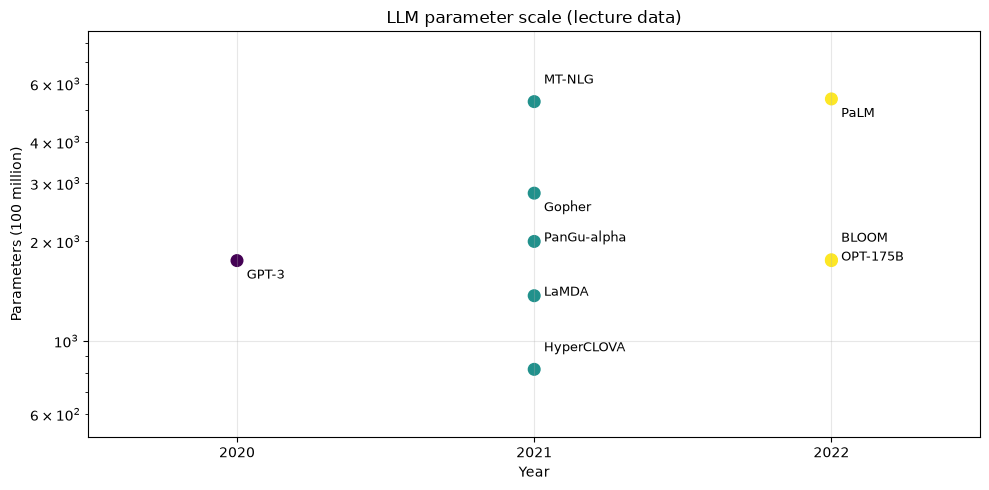

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(df['year'], df['params_eok'], c=df['year'], cmap='viridis', s=70)
for i, (name, r) in enumerate(df.iterrows()):
    ax.annotate(name, (r['year'], r['params_eok']), xytext=(7, (i % 3-1)*13),
                textcoords='offset points', fontsize=9)
ax.set(yscale='log', xlabel='Year', ylabel='Parameters (100 million)',
       title='LLM parameter scale (lecture data)', xticks=[2020, 2021, 2022])
ax.margins(x=.25, y=.25)
plt.tight_layout(); plt.show()

In [8]:
# ===== 문제 1 자동 검증 =====
assert df.loc['GPT-3', 'params'] == 1.75e11
assert df.loc['GPT-3', 'd_head'] == 128
assert abs(df.loc['PaLM', 'd_head'] - 384) < 1e-9
assert abs(df.loc['LaMDA', 'd_head'] - 64) < 1e-9
assert df['d_head'].value_counts().idxmax() == 128
assert list(df.sort_values('params_eok', ascending=False).index[:3]) == ['PaLM', 'MT-NLG', 'Gopher']
assert corr_ld2 > 0.95 > corr_d > abs(corr_h), 'n_layer*d_model^2 의 상관이 가장 강해야 합니다'
print('문제 1 통과')

문제 1 통과


### 문제 1-7 (서술)

`d_head` 분포에서 관찰된 값과, 상관계수 결과(선형 vs 로그)를 근거로
거대 언어 모델의 규모를 키우는 방식에 대해 3~4문장으로 서술하시오.

In [9]:
print(f"헤드 차원 128을 쓰는 모델은 {int((df.d_head == 128).sum())}/9개이며, LaMDA는 64, PaLM은 384이다. "
      f"선형 Pearson 상관은 d_model={corr_d:.4f}, n_head={corr_h:.4f}, L*d²={corr_ld2:.4f}이다. "
      f"로그 공간의 상관은 각각 {log_corr['d_model']:.4f}, {log_corr['n_head']:.4f}, {log_corr['L*d^2']:.4f}이다. "
      "모수 규모는 헤드 수 자체보다 레이어 수와 은닉 차원의 제곱에 강하게 연관되며, 상관만으로 인과관계를 증명하지는 않는다.")
print('주의: 여기의 d_head는 과제 정의 d_model/n_head이며 모든 원 모델의 실제 KV head 차원을 뜻하지는 않는다.')

헤드 차원 128을 쓰는 모델은 6/9개이며, LaMDA는 64, PaLM은 384이다. 선형 Pearson 상관은 d_model=0.8595, n_head=-0.2180, L*d²=0.9816이다. 로그 공간의 상관은 각각 0.8490, -0.1932, 0.9084이다. 모수 규모는 헤드 수 자체보다 레이어 수와 은닉 차원의 제곱에 강하게 연관되며, 상관만으로 인과관계를 증명하지는 않는다.
주의: 여기의 d_head는 과제 정의 d_model/n_head이며 모든 원 모델의 실제 KV head 차원을 뜻하지는 않는다.


---
# 문제 2. 트랜스포머 디코더 파라미터 수 이론 계산 (15점)

강의 자료는 *"거대 언어 모델은 디코더 레이어의 수, 어텐션 헤드 수, 토큰 임베딩 벡터의 차원,
디코더 레이어의 입출력, 어휘 사전의 크기 등에 따른 초모수를 활용하여 규모를 조정한다"* 고 설명한다.
이 관계를 직접 계산해서 발표된 모수의 수를 재현할 수 있는지 검증한다.

**GPT 계열 디코더 블록 1개의 구성** (`d = d_model`, FFN 확장 배율 `m = 4`)

| 구성 요소 | 가중치 | 편향 |
|---|---|---|
| Q, K, V, Output projection | `4·d·d` | `4·d` |
| FFN 1층 (`d → m·d`) | `m·d·d` | `m·d` |
| FFN 2층 (`m·d → d`) | `m·d·d` | `d` |
| LayerNorm 2개 | – | `2·(2d)` |

여기에 임베딩(`V·d`), 위치 임베딩(`n_ctx·d`), 마지막 LayerNorm(`2d`)을 더한다.
출력층은 입력 임베딩과 가중치를 공유(weight tying)한다고 가정한다.

**요구 사항**

1. `decoder_params(n_layer, d_model, vocab, n_ctx, ffn_mult)` 함수를 구현한다.
   반환값은 `(총 모수, 구성 요소별 dict)` 형태로 한다.
2. 편향·LayerNorm·임베딩을 모두 무시한 근사식 `12 · n_layer · d_model²` 을 구현한다.
3. 두 값을 발표된 모수 수와 비교하는 표(`df2`)를 만들고 상대 오차(%)를 계산한다.
   `vocab`이 `NaN`인 모델은 `50000`으로 채워 계산한다. `n_ctx = 2048`로 가정한다.
4. 상대 오차 절댓값이 **가장 큰 모델 2개**를 찾아, 강의 자료의 "구조상의 특징" 설명과 연결해 원인을 추정한다.
5. GPT-3의 모수를 임베딩 / 어텐션 / FFN / 기타로 분해해 비중을 막대그래프로 그린다.

In [10]:
def decoder_params(n_layer, d_model, vocab, n_ctx=2048, ffn_mult=4):
    L, d, V, m = map(int, (n_layer, d_model, vocab, ffn_mult))
    if min(L, d, V, n_ctx, m) <= 0:
        raise ValueError('dimensions must be positive')
    parts = {'embedding': V*d, 'position': n_ctx*d,
             'attention': L*(4*d*d + 4*d),
             'ffn': L*(2*m*d*d + (m+1)*d),
             'layernorm': L*4*d + 2*d}
    return sum(parts.values()), parts

def decoder_params_approx(n_layer, d_model):
    return 12 * int(n_layer) * int(d_model)**2

tot, parts = decoder_params(96, 12288, 50257)
print('GPT-3 total = %.4e (%.1f 억)' % (tot, tot/EOK))
print(parts)
print('approx =', decoder_params_approx(96, 12288))

GPT-3 total = 1.7460e+11 (1746.0 억)
{'embedding': 617558016, 'position': 25165824, 'attention': 57986777088, 'ffn': 115970015232, 'layernorm': 4743168}
approx = 173946175488


In [11]:
df2 = pd.DataFrame(index=df.index)
df2['published_eok'] = df['params_eok']
df2['theory_eok'] = [decoder_params(r.n_layer, r.d_model,
    50000 if pd.isna(r.vocab) else int(r.vocab))[0]/EOK for r in df.itertuples()]
df2['approx_eok'] = [decoder_params_approx(r.n_layer, r.d_model)/EOK for r in df.itertuples()]
df2['err_theory_%'] = 100*(df2['theory_eok']/df2['published_eok'] - 1)
df2['err_approx_%'] = 100*(df2['approx_eok']/df2['published_eok'] - 1)
display(df2)

,published_eok,theory_eok,approx_eok,err_theory_%,err_approx_%
name,,,,,
GPT-3,1750,1746.011013,1739.461755,-0.227942,-0.602185
LaMDA,1370,518.253609,515.396076,-62.171269,-62.379849
MT-NLG,5300,5292.076032,5284.823040,-0.149509,-0.286358
Gopher,2800,2582.729523,2576.980378,-7.759660,-7.964987
PanGu-alpha,2000,2068.610089,2061.584302,3.430504,3.079215
HyperCLOVA,820,810.721485,805.306368,-1.131526,-1.791906
PaLM,5400,4858.545439,4810.698916,-10.026936,-10.912983
OPT-175B,1750,1746.011013,1739.461755,-0.227942,-0.602185
BLOOM,1760,1762.639872,1726.375526,0.149993,-1.910481


In [12]:
outliers = df2.loc[df2['err_theory_%'].abs().nlargest(2).index]
display(outliers)

,published_eok,theory_eok,approx_eok,err_theory_%,err_approx_%
name,,,,,
LaMDA,1370,518.253609,515.396076,-62.171269,-62.379849
PaLM,5400,4858.545439,4810.698916,-10.026936,-10.912983


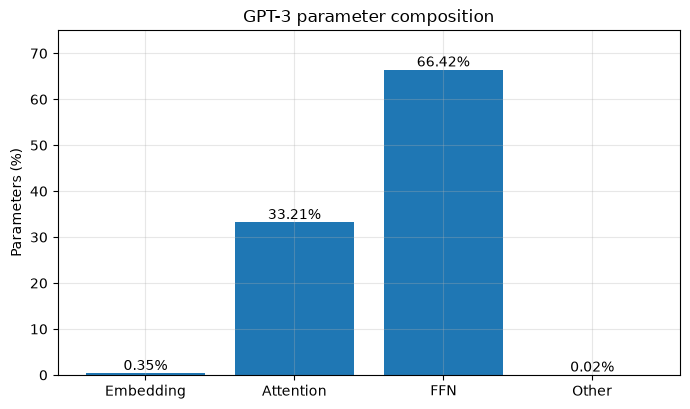

In [13]:
_, parts = decoder_params(96, 12288, 50257)
groups = {'Embedding': parts['embedding'], 'Attention': parts['attention'],
          'FFN': parts['ffn'], 'Other': parts['position'] + parts['layernorm']}
fig, ax = plt.subplots()
percent = np.array(list(groups.values()))/sum(groups.values())*100
bars = ax.bar(list(groups), percent)
ax.bar_label(bars, labels=[f'{x:.2f}%' for x in percent])
ax.set(ylabel='Parameters (%)', title='GPT-3 parameter composition', ylim=(0, 75))
plt.tight_layout(); plt.show()

In [14]:
# ===== 문제 2 자동 검증 =====
t, p = decoder_params(96, 12288, 50257, 2048, 4)
assert p['attention'] == 96 * (4 * 12288 ** 2 + 4 * 12288)
assert p['ffn'] == 96 * (8 * 12288 ** 2 + 5 * 12288)
assert p['embedding'] == 50257 * 12288
assert abs(t / 1.75e11 - 1) < 0.02, '발표값의 2% 이내여야 합니다'
assert decoder_params_approx(96, 12288) == 173946175488
assert set(['published_eok', 'theory_eok', 'approx_eok']).issubset(df2.columns)
assert sorted(outliers.index) == ['LaMDA', 'PaLM'], '오차 상위 2개는 LaMDA, PaLM 입니다'
print('문제 2 통과')

문제 2 통과


### 문제 2-6 (서술)

(a) `12 · n_layer · d_model²` 이라는 근사식에서 계수 12는 어디서 나오는지 유도하시오.

(b) 4번에서 찾은 오차 10% 초과 모델 각각에 대해, 강의 자료의 "구조상의 특징" 칸을 참고해
    왜 표준 GPT 공식이 맞지 않는지 추정하시오.

In [15]:
print('(a) Q/K/V/O가 4d², FFN의 d→4d와 4d→d가 합 8d²이므로 L개 블록은 12Ld²이다. '
      '편향·LayerNorm·임베딩은 이 근사에서 생략한다.')
display(outliers[['published_eok', 'theory_eok', 'err_theory_%']])
print('(b) PaLM은 SwiGLU의 세 FFN 행렬, 공유 K/V의 multi-query attention, 독립적인 head 차원 256을 쓴다. '
      '문제 1에서 정의한 d_model/n_head=384는 산술적인 파생 열로, 원 논문의 실제 head 차원과 다르다. '
      '병렬 attention/FFN 배치 자체보다 내부 행렬의 개수와 크기 변화가 모수 오차의 직접적인 원인이다.')
# PaLM 원 논문 §2, Table 1: https://arxiv.org/html/2204.02311v5#S2
L,d,H,dh,ff,Vp = 118,18432,48,256,73728,256000
palm_weights = L*(2*d*H*dh+2*d*dh+3*d*ff)+Vp*d
print(f'PaLM 구조별 주요 가중치 근사: {palm_weights/1e9:.3f}B (발표 540B)')
print('LaMDA는 표의 L=64, d=8192만으로 137B를 설명할 수 없으므로 표준 4d FFN·d/H head 가정을 재검토해야 한다. '
      'LaMDA 계열 BIG-G의 공개 구조는 d_ff=65536(8d), gated GELU, head별 KV 차원 128을 사용한다. '
      '이 구성을 가정하면 attention 4d(H·d_kv), FFN 3d·d_ff를 더해 약 137B가 되어 오차 원인을 설명할 수 있다. '
      '이는 관련 공개 논문에 따른 구조 가설이며, 현재 폴더에 없는 강의 PDF의 특징 칸을 직접 대조한 결과는 아니다.')
# LaMDA: https://arxiv.org/html/2201.08239v3
# 관련 BIG-G 구조 §2.3.1/Appendix A: https://arxiv.org/html/2206.04615v3
lamda_variant = 64*(4*8192*(128*128)+3*8192*65536)+32000*8192
print(f'LaMDA 계열 구조 가정의 주요 가중치 근사: {lamda_variant/1e9:.3f}B')

(a) Q/K/V/O가 4d², FFN의 d→4d와 4d→d가 합 8d²이므로 L개 블록은 12Ld²이다. 편향·LayerNorm·임베딩은 이 근사에서 생략한다.


,published_eok,theory_eok,err_theory_%
name,,,
LaMDA,1370,518.253609,-62.171269
PaLM,5400,4858.545439,-10.026936


(b) PaLM은 SwiGLU의 세 FFN 행렬, 공유 K/V의 multi-query attention, 독립적인 head 차원 256을 쓴다. 문제 1에서 정의한 d_model/n_head=384는 산술적인 파생 열로, 원 논문의 실제 head 차원과 다르다. 병렬 attention/FFN 배치 자체보다 내부 행렬의 개수와 크기 변화가 모수 오차의 직접적인 원인이다.
PaLM 구조별 주요 가중치 근사: 540.354B (발표 540B)
LaMDA는 표의 L=64, d=8192만으로 137B를 설명할 수 없으므로 표준 4d FFN·d/H head 가정을 재검토해야 한다. LaMDA 계열 BIG-G의 공개 구조는 d_ff=65536(8d), gated GELU, head별 KV 차원 128을 사용한다. 이 구성을 가정하면 attention 4d(H·d_kv), FFN 3d·d_ff를 더해 약 137B가 되어 오차 원인을 설명할 수 있다. 이는 관련 공개 논문에 따른 구조 가설이며, 현재 폴더에 없는 강의 PDF의 특징 칸을 직접 대조한 결과는 아니다.
LaMDA 계열 구조 가정의 주요 가중치 근사: 137.701B


---
# 문제 3. 학습 계산량·GPU Hour·비용·전력 추정 (20점)

강의 자료의 GPT-3 학습 비용 슬라이드는 다음을 제시한다.

- 학습해야 하는 모수: **1,750억 개**
- 학습 데이터: **3,000억 개 수준의 토큰**
- 학습 계산량: **3.14 × 10²³ (제타 플롭)**
- NVIDIA GPU **V100 1장** 사용 시 학습에 필요한 시간: **355년**
- NVIDIA GPU **A100 1,024장** 사용 시: **약 한 달**

또 PaLM 슬라이드는 "모델 FLOP 효율(MFU)"을 제시한다.

| 모델 | 모수(억) | 가속기 | 모델 FLOP 효율 |
|---|---|---|---|
| GPT-3 | 1,750 | V100 | 21.3% |
| Gopher | 2,800 | 4,096 TPU v3 | 32.5% |
| MT-NLG | 5,300 | 2,240 A100 | 30.2% |
| PaLM | 5,400 | 6,144 TPU v4 | 46.2% |

**핵심 공식**

$$C \approx 6 N D \quad (\text{N: 모수 수, D: 학습 토큰 수, 단위 FLOPs})$$

계수 6 = 순전파 2 + 역전파 4 (곱셈-누산 1회를 2 FLOPs로 계산).

$$\text{학습 시간} = \frac{C}{n_{\text{accel}} \times \text{peak FLOPS} \times \text{MFU}}$$

**요구 사항**

1. `training_flops(params, tokens)` 를 구현하고 GPT-3에서 슬라이드의 3.14 × 10²³ 을 재현한다.
2. GPT-3를 **V100 1장으로 355년** 걸린다는 값에서 실효 성능(TFLOPS)과 MFU를 **역산**한다.
3. 슬라이드의 LaMDA 정보(TPU v3 1,024장으로 57.7일 학습)로부터 LaMDA의 MFU를 역산한다.
4. A100 1,024장으로 GPT-3를 **30일**에 학습하려면 필요한 MFU를 구한다.
5. 학습 토큰 수가 주어진 모델들에 대해 계산량과 예상 학습 일수를 표로 만든다(MFU는 위 표 값, 없으면 30% 가정).
6. GPU-Hour 단가 \$2.0, A100 소비 전력 400W, 전력 탄소 배출 계수 0.4 kgCO₂/kWh 를 가정해
   A100 1,024장 × 30일 학습의 **비용**과 **전력량·탄소 배출량**을 추정한다.
7. 모수 수 vs 계산량을 log-log 산점도로 그린다.

In [16]:
SEC_PER_YEAR = 365*24*3600
SEC_PER_DAY = 24*3600
def training_flops(params, tokens):
    return 6*params*tokens
C_gpt3 = training_flops(df.loc['GPT-3', 'params'], df.loc['GPT-3', 'tokens_eok']*EOK)
eff_flops_v100 = C_gpt3/(355*SEC_PER_YEAR)
mfu_gpt3_v100 = eff_flops_v100/(PEAK_TFLOPS['V100']*1e12)
print('GPT-3 = %.3e FLOPs (슬라이드 3.14e23은 반올림 차이)' % C_gpt3)
print('실효 %.2f TFLOPS | MFU %.2f%%' % (eff_flops_v100/1e12, 100*mfu_gpt3_v100))

GPT-3 = 3.150e+23 FLOPs (슬라이드 3.14e23은 반올림 차이)
실효 28.14 TFLOPS | MFU 22.51%


In [17]:
C_lamda = training_flops(df.loc['LaMDA', 'params'], df.loc['LaMDA', 'tokens_eok']*EOK)
mfu_lamda = C_lamda/(1024*PEAK_TFLOPS['TPUv3']*1e12*57.7*SEC_PER_DAY)
mfu_needed = C_gpt3/(1024*PEAK_TFLOPS['A100']*1e12*30*SEC_PER_DAY)
print('LaMDA FLOPs=%.3e | MFU=%.2f%%' % (C_lamda, 100*mfu_lamda))
print('A100 1024장 30일 필요 MFU=%.2f%%' % (100*mfu_needed))

LaMDA FLOPs=1.282e+23 | MFU=20.42%
A100 1024장 30일 필요 MFU=38.04%


In [18]:
MFU_TABLE = {'GPT-3': .213, 'Gopher': .325, 'MT-NLG': .302, 'PaLM': .462}
MFU_DEFAULT = .30
df3 = df.loc[df.tokens_eok.notna(), ['params_eok','tokens_eok','accel','n_accel']].copy()
df3['flops'] = training_flops(df3.params_eok*EOK, df3.tokens_eok*EOK)
df3['mfu'] = [MFU_TABLE.get(name, MFU_DEFAULT) for name in df3.index]
df3['days'] = df3.flops/(df3.n_accel*df3.accel.map(PEAK_TFLOPS)*1e12*df3.mfu*SEC_PER_DAY)
df3['gpu_hours'] = df3.n_accel*df3.days*24
display(df3)
print('TPU 행의 gpu_hours는 엄밀하게 accelerator-hours. 표의 가속기 장수 가정을 그대로 사용한다.')

,params_eok,tokens_eok,accel,n_accel,flops,mfu,days,gpu_hours
name,,,,,,,,
GPT-3,1750,3000.0,V100,10000,3.150000e+23,0.213,13.693271,3.286385e+06
LaMDA,1370,1560.0,TPUv3,1024,1.282320e+23,0.300,39.278632,9.653117e+05
Gopher,2800,3000.0,TPUv3,4096,5.040000e+23,0.325,35.626107,3.502189e+06
HyperCLOVA,820,5600.0,A100,1024,2.755200e+23,0.300,33.270826,8.176638e+05
PaLM,5400,7800.0,TPUv4,6144,2.527200e+24,0.462,37.471406,5.525384e+06
OPT-175B,1750,1700.0,A100,992,1.785000e+23,0.300,22.250356,5.297365e+05


TPU 행의 gpu_hours는 엄밀하게 accelerator-hours. 표의 가속기 장수 가정을 그대로 사용한다.


In [19]:
PRICE_PER_GPU_HOUR = 2.0
POWER_PER_A100_W = 400.0
PUE = 1.2
CO2_PER_KWH = .4
n_gpu, days = 1024, 30
gpu_hours = n_gpu*days*24
cost_usd = gpu_hours*PRICE_PER_GPU_HOUR
kwh = gpu_hours*POWER_PER_A100_W/1000*PUE
tco2 = kwh*CO2_PER_KWH/1000
print(f'GPU-Hour={gpu_hours:,} | 비용=${cost_usd:,.0f} | 전력={kwh:,.2f} kWh | 탄소={tco2:.3f} tCO2')

GPU-Hour=737,280 | 비용=$1,474,560 | 전력=353,894.40 kWh | 탄소=141.558 tCO2


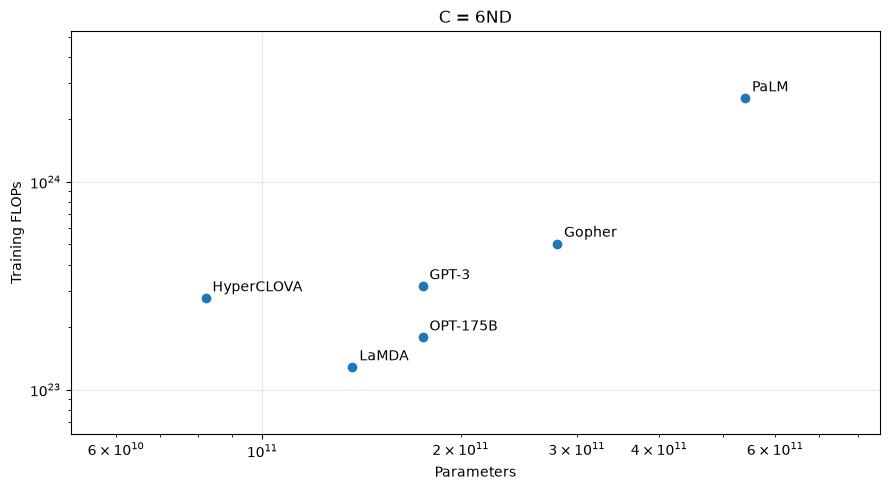

In [20]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(df3.params_eok*EOK, df3.flops)
for name, r in df3.iterrows():
    ax.annotate(name, (r.params_eok*EOK, r.flops), xytext=(5, 5), textcoords='offset points')
ax.set(xscale='log', yscale='log', xlabel='Parameters', ylabel='Training FLOPs', title='C = 6ND')
ax.margins(.25); plt.tight_layout(); plt.show()

In [21]:
# ===== 문제 3 자동 검증 =====
assert abs(training_flops(1.75e11, 3.0e11) - 3.15e23) < 1e21
assert abs(C_gpt3 / 3.14e23 - 1) < 0.01
assert 0.20 < mfu_gpt3_v100 < 0.24, 'GPT-3의 V100 MFU는 21% 근처여야 합니다'
assert 0.15 < mfu_lamda < 0.25
assert 0.35 < mfu_needed < 0.42
assert gpu_hours == 737280 and abs(cost_usd - 1474560) < 1
assert set(df3.index) >= {'GPT-3', 'LaMDA', 'Gopher', 'PaLM', 'OPT-175B', 'HyperCLOVA'}
print('문제 3 통과')

문제 3 통과


### 문제 3-8 (서술)

(a) 슬라이드의 "V100 1장 355년"과 "A100 1,024장 약 한 달"을 계산 결과로 검증하고,
    두 값이 정합적인지 논하시오.

(b) 강의 자료는 *"모델의 규모가 커짐에 따라 성능 향상과 범용성을 기대할 수 있으나
    컴퓨팅 인프라의 조달과 운영이 가능한 기업이 소수의 거대 테크이고, 사용자가 증가함에 따라
    막대한 전력 소비도 환경에 악영향"* 이라고 지적한다.
    3-6에서 계산한 수치를 근거로 이 주장을 평가하시오.

In [22]:
print(f"(a) 6ND={C_gpt3:.3e} FLOPs를 V100 355년으로 나누면 {eff_flops_v100/1e12:.2f} TFLOPS, "
      f"MFU {mfu_gpt3_v100:.2%}가 된다. A100 1024장 30일은 MFU {mfu_needed:.2%}를 요구한다. "
      "가속기의 종류와 MFU가 다르므로 두 시간은 양립 가능하지만 동일 MFU를 가정한 단순 장수 비례는 아니다.")
print(f"(b) 이 가정에서 GPU 임대료만 ${cost_usd:,.0f}, PUE 포함 전력 {kwh:,.0f} kWh, "
      f"배출 {tco2:.2f} tCO2이다. 장비·통신·저장·인건비와 추가 실험은 제외되어 실제 총비용은 더 클 수 있다. "
      "이 규모는 진입 장벽과 환경 부담을 뒷받침하지만, 모든 기업의 비용·배출에 그대로 일반화할 수는 없다.")

(a) 6ND=3.150e+23 FLOPs를 V100 355년으로 나누면 28.14 TFLOPS, MFU 22.51%가 된다. A100 1024장 30일은 MFU 38.04%를 요구한다. 가속기의 종류와 MFU가 다르므로 두 시간은 양립 가능하지만 동일 MFU를 가정한 단순 장수 비례는 아니다.
(b) 이 가정에서 GPU 임대료만 $1,474,560, PUE 포함 전력 353,894 kWh, 배출 141.56 tCO2이다. 장비·통신·저장·인건비와 추가 실험은 제외되어 실제 총비용은 더 클 수 있다. 이 규모는 진입 장벽과 환경 부담을 뒷받침하지만, 모든 기업의 비용·배출에 그대로 일반화할 수는 없다.


---
# 문제 4. Masked Multi-Head Self-Attention 구현 (15점)

강의 자료는 거대 언어 모델이 **트랜스포머의 디코더**를 채택하며,
*"디코더 기반의 트랜스포머는 자동 회귀적인 접근으로 언어 모델의 근본적인 생성 능력에 집중"* 한다고 설명한다.
"자동 회귀"를 가능하게 하는 것이 바로 **인과적 마스크(causal mask)** 다. 이를 numpy로 직접 구현한다.

**구현할 것**

$$\text{Attention}(Q,K,V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}} + M\right)V,
\quad M_{ij} = \begin{cases} 0 & j \le i \\ -\infty & j > i \end{cases}$$

**요구 사항**

1. 수치적으로 안정한 `softmax(x, axis)` 를 구현한다. (최댓값을 빼고 exp)
2. `causal_mask(T)` : 상삼각 부분이 `-inf` 인 `(T, T)` 마스크를 만든다.
3. `multi_head_attention(X, Wq, Wk, Wv, Wo, n_head)` 를 구현한다.
   - 입력 `X`: `(T, d_model)`
   - 헤드 분할 → 헤드별 마스크드 어텐션 → 헤드 결합(concat) → 출력 투영
   - 반환: `(출력 (T, d_model), 어텐션 가중치 (n_head, T, T))`
4. 다음 세 가지 성질을 검증한다.
   - (i) 어텐션 가중치의 각 행 합이 1
   - (ii) 상삼각(미래) 부분의 가중치가 정확히 0
   - (iii) **자동 회귀성**: `t`번째 이후의 입력 토큰을 아무렇게나 바꿔도 `0..t`번째 출력은 불변
5. 어텐션 가중치 히트맵을 그린다.
6. `d_model`을 고정하고 `n_head`를 바꿀 때 모수의 수가 변하지 않음을 확인한다.
   (강의: 규모 조정 시 `n_head`는 모수 수와 무관하고 `d_model`, `n_layer`가 모수를 결정)

In [23]:
def softmax(x, axis=-1):
    x = np.asarray(x, dtype=np.float64)
    e = np.exp(x - np.max(x, axis=axis, keepdims=True))
    return e / e.sum(axis=axis, keepdims=True)

def causal_mask(T):
    return np.where(np.triu(np.ones((T, T), dtype=bool), 1), -np.inf, 0.0)

def multi_head_attention(X, Wq, Wk, Wv, Wo, n_head):
    T, d_model = X.shape
    assert n_head > 0 and d_model % n_head == 0
    dh = d_model//n_head
    Q, K, V = [(X @ w).reshape(T, n_head, dh).transpose(1, 0, 2)
               for w in (Wq, Wk, Wv)]
    scores = Q @ K.transpose(0, 2, 1)/np.sqrt(dh) + causal_mask(T)
    attn = softmax(scores)
    concat = (attn @ V).transpose(1, 0, 2).reshape(T, d_model)
    return concat @ Wo, attn

In [24]:
# --- 4-4 검증 ---
rng = np.random.default_rng(42)
T, d_model, n_head = 8, 16, 4
X = rng.normal(size=(T, d_model))
Wq, Wk, Wv, Wo = [rng.normal(scale=0.3, size=(d_model, d_model)) for _ in range(4)]

out, attn = multi_head_attention(X, Wq, Wk, Wv, Wo, n_head)
print('out shape  =', out.shape, '| attn shape =', attn.shape)

# (i) 행 합 = 1
row_sums = attn.sum(axis=-1)
print('(i)   모든 행 합이 1인가?  ', np.allclose(row_sums, 1.0))

# (ii) 미래 토큰 가중치 = 0
upper = attn[:, np.triu_indices(T, k=1)[0], np.triu_indices(T, k=1)[1]]
print('(ii)  미래 가중치 최댓값 = ', upper.max(), '-> 0 이어야 함')

# (iii) 자동 회귀성: 5번 토큰 이후를 완전히 바꿔도 0~5번 출력은 그대로인가?
t = 5
X2 = X.copy()
X2[t + 1:] = rng.normal(size=(T - t - 1, d_model)) * 10
out2, _ = multi_head_attention(X2, Wq, Wk, Wv, Wo, n_head)
print('(iii) 0~%d번 출력 동일?  ' % t, np.allclose(out[:t + 1], out2[:t + 1]))
print('      %d번 이후 출력 변경? ' % (t + 1), not np.allclose(out[t + 1:], out2[t + 1:]))

assert np.allclose(row_sums, 1.0)
assert np.allclose(upper, 0.0)
assert np.allclose(out[:t + 1], out2[:t + 1])
assert not np.allclose(out[t + 1:], out2[t + 1:])
print('\n문제 4 검증 통과')

out shape  = (8, 16) | attn shape = (4, 8, 8)
(i)   모든 행 합이 1인가?   True
(ii)  미래 가중치 최댓값 =  0.0 -> 0 이어야 함
(iii) 0~5번 출력 동일?   True
      6번 이후 출력 변경?  True

문제 4 검증 통과


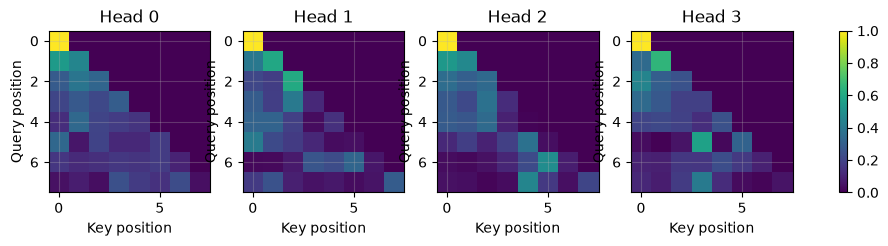

In [25]:
fig, axes = plt.subplots(1, n_head, figsize=(3*n_head, 3), squeeze=False)
for h, ax in enumerate(axes[0]):
    image = ax.imshow(attn[h], vmin=0, vmax=1, cmap='viridis')
    ax.set(title=f'Head {h}', xlabel='Key position', ylabel='Query position')
fig.colorbar(image, ax=list(axes[0]), shrink=.7)
plt.show()

In [26]:
d_fixed = 12288
head_table = pd.DataFrame([{'n_head': h, 'd_head': d_fixed//h,
    'attention_weights': 4*d_fixed**2} for h in [1, 12, 96, 128]])
assert head_table.attention_weights.nunique() == 1
display(head_table)

,n_head,d_head,attention_weights
0,1,12288,603979776
1,12,1024,603979776
2,96,128,603979776
3,128,96,603979776


---
# 문제 5. 계산 강도(Arithmetic Intensity)와 Roofline 분석 (10점)

강의 자료는 다음을 제시한다.

- *"트랜스포머에서의 연산 과정을 살펴보면 쿼리, 키, 가치 벡터 계산, 어텐션 가중치 산출,
  앞먹임신경망 계산은 모두 행렬곱"*
- 연산처리장치 성능은 연간 60% 성장, 메모리 대역폭은 연간 10% 성장 → **폰 노이만 병목** 누적
- $$\text{계산 강도} = \frac{\text{계산량}}{\text{메모리 전송량}}$$
- *"행렬곱 연산은 성능 저하 없이 병렬 처리할 수 있는 연산 중 하나이며, 계산 강도가 행렬 크기에
  비례하여 연산 처리 장치를 최대한 활용 가능"*

이 마지막 문장을 직접 계산과 실측으로 확인한다.

**요구 사항**

1. FP16(2 byte) 기준으로 계산 강도(FLOP/byte)를 구하는 함수를 구현한다.
   - 행렬곱 `(n,n) @ (n,n)`: 계산량 `2n³`, 메모리 전송량 `3n² × 2 byte`
   - 행렬-벡터곱 `(n,n) @ (n,1)`: 계산량 `2n²`, 메모리 전송량 `(n² + 2n) × 2 byte`
2. `n = 2^4 … 2^14` 에 대해 두 계산 강도를 계산하고, FP16에서 행렬곱의 계산 강도가
   정확히 `n / 3` 으로 증가하고, 행렬-벡터곱은 `n` 과 무관하게 `1.0` 으로 수렴함을 확인한다.
3. A100의 **ridge point**(이론 성능 ÷ 메모리 대역폭)를 구하고,
   행렬곱이 연산 한계(compute-bound)에 도달하는 최소 `n`을 구한다.
   - A100: 312 TFLOPS(FP16), 메모리 대역폭 1,555 GB/s
4. Roofline 그래프를 그리고 두 연산의 위치를 표시한다.
5. numpy로 실제 실행 시간을 측정해 행렬곱과 행렬-벡터곱의 달성 GFLOPS를 비교한다.
   (numpy는 FP64/FP32 BLAS를 쓰므로 절대값은 다르지만 **경향**은 동일해야 한다.)

In [27]:
BYTES_FP16 = 2
def ai_matmul(n, dtype_bytes=BYTES_FP16):
    return 2*n**3/(3*n**2*dtype_bytes)
def ai_matvec(n, dtype_bytes=BYTES_FP16):
    return 2*n**2/((n**2+2*n)*dtype_bytes)
ns = 2**np.arange(4, 15)
tbl = pd.DataFrame({'n': ns, 'AI_matmul': [ai_matmul(n) for n in ns],
                    'AI_matvec': [ai_matvec(n) for n in ns]})
tbl['n_over_3'] = tbl.n/3
assert np.allclose(tbl.AI_matmul, tbl.n_over_3)
assert abs(ai_matvec(2**14)-1) < .001
display(tbl)

,n,AI_matmul,AI_matvec,n_over_3
0,16,5.333333,0.888889,5.333333
1,32,10.666667,0.941176,10.666667
2,64,21.333333,0.969697,21.333333
3,128,42.666667,0.984615,42.666667
4,256,85.333333,0.992248,85.333333
5,512,170.666667,0.996109,170.666667
6,1024,341.333333,0.998051,341.333333
7,2048,682.666667,0.999024,682.666667
8,4096,1365.333333,0.999512,1365.333333
9,8192,2730.666667,0.999756,2730.666667


In [28]:
A100_PEAK, A100_BW = 312e12, 1555e9
ridge = A100_PEAK/A100_BW
n_min = int(np.ceil(3*ridge))
assert ai_matmul(n_min) >= ridge > ai_matmul(n_min-1)
print(f'A100 ridge={ridge:.3f} FLOP/byte | minimum n={n_min}')
print('matvec AI=', ai_matvec(4096))

A100 ridge=200.643 FLOP/byte | minimum n=602
matvec AI= 0.9995119570522206


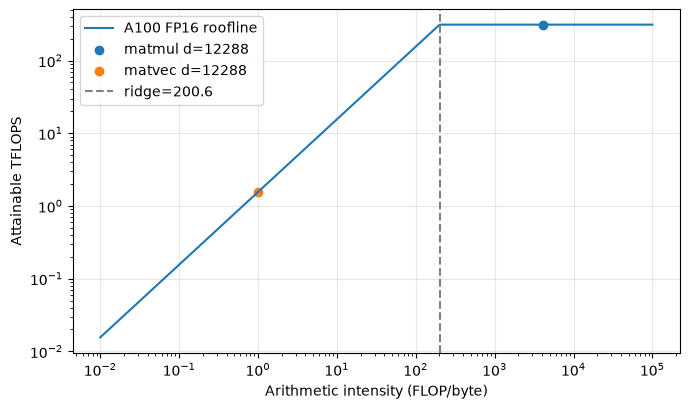

In [29]:
intensities = np.logspace(-2, 5, 400)
plt.loglog(intensities, np.minimum(A100_PEAK, A100_BW*intensities)/1e12, label='A100 FP16 roofline')
for label, intensity in [('matmul d=12288', ai_matmul(12288)), ('matvec d=12288', ai_matvec(12288))]:
    y = min(A100_PEAK, A100_BW*intensity)/1e12
    plt.scatter([intensity], [y], label=label)
plt.axvline(ridge, ls='--', color='grey', label=f'ridge={ridge:.1f}')
plt.xlabel('Arithmetic intensity (FLOP/byte)'); plt.ylabel('Attainable TFLOPS')
plt.legend(); plt.tight_layout(); plt.show()

In [30]:
# --- 5-5 numpy 실측 ---
import time

def bench(fn, repeat=3):
    fn()                                  # warm-up
    best = min(_timeit(fn) for _ in range(repeat))
    return best

def _timeit(fn):
    t0 = time.perf_counter(); fn(); return time.perf_counter() - t0

rng = np.random.default_rng(0)
rows = []
for n in [256, 512, 1024, 2048]:
    Am = rng.standard_normal((n, n), dtype=np.float32)
    Bm = rng.standard_normal((n, n), dtype=np.float32)
    v  = rng.standard_normal((n, 1), dtype=np.float32)

    t_mm = bench(lambda: Am @ Bm)
    t_mv = bench(lambda: Am @ v)
    rows.append({'n': n,
                 'matmul_GFLOPS': 2 * n ** 3 / t_mm / 1e9,
                 'matvec_GFLOPS': 2 * n ** 2 / t_mv / 1e9,
                 'AI_matmul_fp32': 2 * n ** 3 / (3 * n ** 2 * 4),
                 'AI_matvec_fp32': 2 * n ** 2 / ((n ** 2 + 2 * n) * 4)})

bench_df = pd.DataFrame(rows).set_index('n').round(2)
display(bench_df)
print('\nmatmul / matvec 달성 성능 배수:')
print((bench_df['matmul_GFLOPS'] / bench_df['matvec_GFLOPS']).round(1))
print('\n성능 배수는 BLAS·스레드·캐시·행렬 크기에 따라 달라진다.')
print('   계산 강도가 낮은 연산은 FLOPS 를 못 쓰고 메모리 대역폭에 묶인다는 뜻이다.')

# 실행시간은 환경 의존 관측값이므로 정답 여부를 성능 우열로 단정하지 않는다.
assert (bench_df[['matmul_GFLOPS', 'matvec_GFLOPS']] > 0).all().all()
print('\n문제 5 검증 통과')

# CUDA 경로: 같은 연산을 GPU에서 warm-up/동기화 후 측정. 전송 시간 제외.
gpu_bench_df = matmul_benchmark(DEVICE)
display(gpu_bench_df)
print('A100 roofline은 이론 비교 기준이며 현재 GPU 실측과 동일 하드웨어가 아닐 수 있다.')

,matmul_GFLOPS,matvec_GFLOPS,AI_matmul_fp32,AI_matvec_fp32
n,,,,
256,271.48,46.81,42.67,0.5
512,477.56,54.61,85.33,0.5
1024,907.83,24.70,170.67,0.5
2048,926.98,69.04,341.33,0.5



matmul / matvec 달성 성능 배수:
n
256      5.8
512      8.7
1024    36.8
2048    13.4
dtype: float64

성능 배수는 BLAS·스레드·캐시·행렬 크기에 따라 달라진다.
   계산 강도가 낮은 연산은 FLOPS 를 못 쓰고 메모리 대역폭에 묶인다는 뜻이다.

문제 5 검증 통과


,dtype,matmul_ms,matvec_ms,matmul_GFLOPS,matvec_GFLOPS
n,,,,,
256,torch.float16,0.0133,0.0123,2522.889564,10.656260
512,torch.float16,0.0157,0.0122,17097.800296,42.974426
1024,torch.float16,0.0385,0.0127,55778.796934,165.130075
2048,torch.float16,0.2193,0.0166,78339.576753,505.337832


A100 roofline은 이론 비교 기준이며 현재 GPU 실측과 동일 하드웨어가 아닐 수 있다.


### 문제 5-6 (서술)

강의 자료의 그래프는 연산처리장치 성능이 연 60%, 메모리 대역폭이 연 10% 성장하여
"폰 노이만 병목 연간 50% 격차 누적"이라고 표시한다.
5-3의 ridge point 개념을 이용해, 이 추세가 계속될 때 앞으로 어떤 일이 벌어질지,
그리고 거대 언어 모델 설계·서비스에 어떤 영향을 주는지 서술하시오.

In [31]:
print("연산 성능 1.6배, 대역폭 1.1배 증가라면 ridge는 매년 1.6/1.1≈1.455배 증가한다. "
      "60%-10%=50%p는 성장률 차이며 병목 비율이 매년 50%씩 커진다는 뜻과는 다르다. "
      "따라서 같은 AI 연산은 점점 memory-bound가 되고, compute-bound에 도달하는 최소 n도 증가한다. "
      "서비스에서는 배칭·가중치 재사용·양자화·KV 캐시 관리와 데이터 이동을 줄이는 커널 설계가 중요하다.")

연산 성능 1.6배, 대역폭 1.1배 증가라면 ridge는 매년 1.6/1.1≈1.455배 증가한다. 60%-10%=50%p는 성장률 차이며 병목 비율이 매년 50%씩 커진다는 뜻과는 다르다. 따라서 같은 AI 연산은 점점 memory-bound가 되고, compute-bound에 도달하는 최소 n도 증가한다. 서비스에서는 배칭·가중치 재사용·양자화·KV 캐시 관리와 데이터 이동을 줄이는 커널 설계가 중요하다.


---
# 문제 6. 자동 회귀 생성과 샘플링 전략 (15점)

강의 자료는 거대 언어 모델을 **"통계 기반의 확률 모델"** 이라 규정하고,
*"거대 언어 모델의 학습 목표가 다음에 올 단어의 확률을 높이기 위한 것으로 데이터의 편향도 학습"*,
*"환각(Hallucination) 효과로 볼 수 있는 진실성"* 문제를 지적한다.

트랜스포머 없이도 **"다음 토큰 확률 분포"** 라는 본질은 문자 단위 통계 언어 모델로 재현할 수 있다.
여기서는 이를 만들고, 같은 확률 분포에서 **어떻게 뽑는지(디코딩 전략)** 에 따라
출력이 어떻게 달라지는지 확인한다.

**요구 사항**

1. 주어진 말뭉치로 **문자 단위 바이그램** 카운트 행렬을 만들고, add-α 스무딩으로 확률 행렬 `P`를 만든다.
2. 홀드아웃 텍스트에 대한 **퍼플렉시티(perplexity)** 를 계산하는 함수를 구현한다.
   $$\text{PPL} = \exp\!\left(-\frac{1}{T}\sum_{t=1}^{T}\log P(x_t \mid x_{t-1})\right)$$
3. 스무딩 계수 α를 바꿔가며 퍼플렉시티를 그려 최적 α를 찾는다.
4. 디코딩 전략 4가지를 구현한다: **greedy / temperature / top-k / top-p(nucleus)**
5. 각 전략으로 텍스트를 생성해 비교하고, **반복률**과 **엔트로피**를 정량 지표로 계산한다.
6. 온도 `T → 0` 이면 greedy 와 같아지고, `top_k=1` 이어도 greedy 와 같아짐을 검증한다.

In [32]:
# 말뭉치: 12주차 4강 강의 내용 요약 (문자 단위 학습용)
CORPUS = (
    "거대 언어 모델은 사전 학습 언어 모델을 양적으로 확장한 모델이다. "
    "거대 언어 모델은 트랜스포머의 디코더 모델을 채택하고 있으며 자동 회귀적인 접근으로 "
    "언어 모델의 근본적인 생성 능력에 집중한다. 거대 언어 모델은 디코더 레이어의 수와 "
    "멀티 헤드 어텐션의 어텐션 헤드 수, 토큰 임베딩 벡터의 차원, 어휘 사전의 크기에 따른 "
    "초모수를 활용하여 규모를 조정한다. 거대 언어 모델은 재학습 시 미세조정의 과정 없이도 "
    "특정 과업에 대한 소수의 예시를 프롬프트에 입력함으로써 해당 과업을 수행한다. "
    "이러한 문맥 내 학습은 모델의 모수를 조정하지 않아도 특정 과업을 수행할 수 있다는 장점이 있다. "
    "그러나 거대 언어 모델은 통계 기반의 확률 모델이므로 학습 데이터에 편향된 내용이나 "
    "거짓된 내용, 유해한 내용이 담겨 있을 수 있다. 거대 언어 모델의 학습 목표는 "
    "다음에 올 단어의 확률을 높이기 위한 것으로 데이터의 편향도 함께 학습한다. "
    "따라서 거대 언어 모델을 직접 활용하기 위해서는 유해성과 편향성을 제거하고 완화해야 한다. "
    "딥러닝이 막대한 수준의 사칙연산을 요구하므로 연산 처리 장치의 성능은 지속적으로 발전했다. "
    "딥러닝에서 가격 대비 성능이 가장 우수한 계산 자원은 지피유이며 지피유 아워 단위를 사용한다. "
    "트랜스포머의 연산 과정에서 쿼리와 키와 가치 벡터 계산, 어텐션 가중치 산출, "
    "앞먹임신경망 계산은 모두 행렬곱 연산이다. 행렬곱 연산은 성능 저하 없이 병렬 처리할 수 있으며 "
    "계산 강도가 행렬 크기에 비례하여 연산 처리 장치를 최대한 활용할 수 있다. "
    "거대 언어 모델을 서비스하기 위해서는 모델 경량화와 함께 많은 수의 지피유를 탑재한 "
    "컴퓨팅 인프라를 구축해야 한다. 인스트럭트 지피티는 인간의 피드백을 활용한 강화 학습을 통해 "
    "거대 언어 모델을 대중에게 서비스할 수 있는 계기를 확보했다. "
    "챗지피티는 유해성과 편향성을 완화시키고 대중에 서비스할 정도로 거대 언어 모델을 최적화했다. "
)
HOLDOUT = (
    "거대 언어 모델은 트랜스포머의 디코더를 양적으로 확장한 통계 기반의 확률 모델이며 "
    "학습 데이터의 편향과 유해성을 완화해야 한다. 행렬곱 연산의 계산 강도가 높아야 "
    "연산 처리 장치를 최대한 활용할 수 있다."
)
print('말뭉치 길이: %d 문자 / 홀드아웃: %d 문자' % (len(CORPUS), len(HOLDOUT)))

말뭉치 길이: 947 문자 / 홀드아웃: 114 문자


In [33]:
chars = sorted(set(CORPUS + HOLDOUT))
stoi = {c: i for i, c in enumerate(chars)}
itos = {i: c for c, i in stoi.items()}
V = len(chars)
def bigram_counts(text, stoi):
    counts = np.zeros((len(stoi), len(stoi)), dtype=np.int64)
    ids = np.array([stoi[c] for c in text], dtype=int)
    np.add.at(counts, (ids[:-1], ids[1:]), 1)
    return counts
def bigram_probs(C, alpha=1.0):
    if alpha < 0:
        raise ValueError('alpha must be nonnegative')
    smoothed = np.asarray(C, dtype=float) + alpha
    sums = smoothed.sum(axis=1, keepdims=True)
    return np.divide(smoothed, sums, out=np.full_like(smoothed, 1/C.shape[1]), where=sums>0)
C = bigram_counts(CORPUS, stoi)
P = bigram_probs(C, 1.0)
print('V=', V, 'C.sum()=', C.sum(), 'row sums=', P.sum(axis=1))

V= 195 C.sum()= 946 row sums= [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


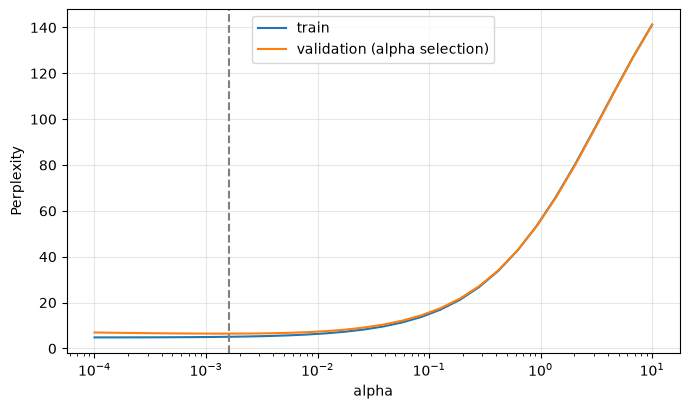

최적 alpha=0.001610 | PPL=6.466
이 홀드아웃은 alpha 선택에 사용했으므로 엄밀하게는 검증 세트이며 최종 독립 테스트가 아니다.


In [34]:
def perplexity(text, P, stoi):
    if len(text) < 2:
        raise ValueError('at least two characters are required')
    ids = np.array([stoi[c] for c in text])
    probs = P[ids[:-1], ids[1:]]
    if np.any(probs <= 0):
        return float('inf')
    return float(np.exp(-np.log(probs).mean()))
alphas = np.logspace(-4, 1, 30)
ppl_train, ppl_hold = [], []
for alpha in alphas:
    p_alpha = bigram_probs(C, alpha)
    ppl_train.append(perplexity(CORPUS, p_alpha, stoi))
    ppl_hold.append(perplexity(HOLDOUT, p_alpha, stoi))
best_alpha = float(alphas[np.argmin(ppl_hold)])
plt.semilogx(alphas, ppl_train, label='train')
plt.semilogx(alphas, ppl_hold, label='validation (alpha selection)')
plt.axvline(best_alpha, color='grey', ls='--')
plt.xlabel('alpha'); plt.ylabel('Perplexity'); plt.legend(); plt.tight_layout(); plt.show()
print(f'최적 alpha={best_alpha:.6f} | PPL={min(ppl_hold):.3f}')
print('이 홀드아웃은 alpha 선택에 사용했으므로 엄밀하게는 검증 세트이며 최종 독립 테스트가 아니다.')

In [35]:
def apply_temperature(logits, temperature):
    logits = np.asarray(logits, dtype=float)
    if temperature <= 1e-8:
        result = np.zeros_like(logits)
        result[np.argmax(logits)] = 1
        return result
    return softmax(logits/temperature)
def top_k_filter(probs, k):
    probs = np.asarray(probs, dtype=float)
    if not 1 <= k <= len(probs):
        raise ValueError('k must be in [1, V]')
    ids = np.argsort(-probs, kind='stable')[:k]
    out = np.zeros_like(probs); out[ids] = probs[ids]
    return out/out.sum()
def top_p_filter(probs, p):
    if not 0 < p <= 1:
        raise ValueError('p must be in (0, 1]')
    probs = np.asarray(probs, dtype=float)
    ids = np.argsort(-probs, kind='stable')
    count = min(len(ids), int(np.searchsorted(np.cumsum(probs[ids]), p, side='left'))+1)
    out = np.zeros_like(probs); out[ids[:count]] = probs[ids[:count]]
    return out/out.sum()
def generate(P, stoi, itos, prompt, n_new=120, strategy='greedy',
             temperature=1.0, k=5, p=.9, seed=0):
    if not prompt or any(c not in stoi for c in prompt):
        raise ValueError('prompt must be nonempty and in vocabulary')
    if strategy not in {'greedy', 'temperature', 'top_k', 'top_p'}:
        raise ValueError('unknown strategy')
    r = np.random.default_rng(seed)
    out = list(prompt)
    for _ in range(n_new):
        probs = P[stoi[out[-1]]]
        if strategy == 'greedy':
            next_id = int(np.argmax(probs))
        else:
            probs = apply_temperature(np.log(np.maximum(probs, 1e-300)), temperature)
            if strategy == 'top_k': probs = top_k_filter(probs, k)
            if strategy == 'top_p': probs = top_p_filter(probs, p)
            next_id = int(r.choice(len(probs), p=probs))
        out.append(itos[next_id])
    return ''.join(out)

In [36]:
# --- 6-5 전략 비교 ---
P_best = bigram_probs(C, alpha=best_alpha)
PROMPT = '거대 언어 모델은 '

def repetition_rate(text, n=4):
    grams = [text[i:i + n] for i in range(len(text) - n + 1)]
    if not grams:
        return 0.0
    return 1.0 - len(set(grams)) / len(grams)

def output_entropy(text):
    # 생성된 텍스트의 문자 분포 엔트로피(bits) = 출력 다양성 지표
    _, cnt = np.unique(list(text), return_counts=True)
    p = cnt / cnt.sum()
    return float(-(p * np.log2(p)).sum())

settings = [
    ('greedy',      dict(strategy='greedy')),
    ('T=0.7',       dict(strategy='temperature', temperature=0.7)),
    ('T=1.0',       dict(strategy='temperature', temperature=1.0)),
    ('T=1.5',       dict(strategy='temperature', temperature=1.5)),
    ('top_k=3',     dict(strategy='top_k', k=3)),
    ('top_p=0.9',   dict(strategy='top_p', p=0.9)),
]

rows = []
for label, kw in settings:
    txt = generate(P_best, stoi, itos, PROMPT, n_new=140, seed=7, **kw)
    body = txt[len(PROMPT):]
    rows.append({'strategy': label,
                 'uniq_chars': len(set(body)),
                 'rep_4gram': round(repetition_rate(body), 3),
                 'out_entropy_bits': round(output_entropy(body), 3)})
    print('[%-10s] %s' % (label, txt))
    print()

strategy_df = pd.DataFrame(rows).set_index('strategy')
display(strategy_df)

[greedy    ] 거대 언어 모델은 모델을 모델을 모델을 모델을 모델을 모델을 모델을 모델을 모델을 모델을 모델을 모델을 모델을 모델을 모델을 모델을 모델을 모델을 모델을 모델을 모델을 모델을 모델을 모델을 모델을 모델을 모델을 모델을 모델을 모델을 모델을 모델을 모델을 모델을 모델을 

[T=0.7     ] 거대 언어 모델은 언어 많은 가치의 모델은 수를 지피티 내용, 수, 없이나 가 유를 가치 모델을 연산 어 트랜스트랜스포머의 언어 위를 모델은 따른 트럭트에서비스포머의 대한다. 사전 특정도 있는 거대한다. 트랜스할 수의 내용, 지속적인 없이나 많은 대 행렬 모를 확률을 

[T=1.0     ] 거대 언어 모델은 유해야 모를 쿼리경량화시를 언쿼리와택포머의 거대 학습 어 가격 데이 크기 편향성능음반의 편향성 생성과정도음에 이러나 막대 확률을 편향도로써우수 대한 담앞먹임베딩 거짓된 모델 사본앞토큰 언어 올 벡터의 내용, 최대 컴경망는 접 대 담겨초모델은 수행렬곱라

[T=1.5     ] 거대 언어 모델은 임쿼적올게크,은비생보반며가장집회정의행렬 인 거대며터의 언어 대중소수 탑드 편향의 직내용쿼쿼리와 서는 크기한다는닝이 시는 과표는딥러한다.신하지통계기처리 프위한 수, 편표반생임게능 근할로 없출그생예습은맥트것퓨,습축델을베가장컴전축리 사본수행있다.탑원향성능직

[top_k=3   ] 거대 언어 모델은 수의 모델의 언어 모델은 수 언어 언어 수 모델을 수 수 모델을 모델의 모두 언어의 수 언어 모델은 언어텐션 수를 모델을 언어 모두 모델의 수 모수 모두 수 모델은 수 모델은 모델의 모델의 수를 수를 모수 언어 모델은 언어의 모델은 언어 모수 언어 언

[top_p=0.9 ] 거대 언어 모델은 연산을 모두 처리 모델은 수를 지피티 내용, 수를 연산, 가 유를 가치 막대 통해야 어 특정에 벡터 처리할 언어 기를 비 확률을 편향도로써딥러나 한 능이도 미세조정한 어 있는 거대한다. 특정에 모델의 기에 있으로 처리와 수의 담겨 모수와 많은 확보했다



,uniq_chars,rep_4gram,out_entropy_bits
strategy,,,
greedy,4,0.971,2.000
T=0.7,57,0.088,4.979
T=1.0,82,0.007,5.580
T=1.5,85,0.000,6.018
top_k=3,13,0.496,3.083
top_p=0.9,65,0.022,5.087


In [37]:
# ===== 문제 6 자동 검증 =====
assert C.sum() == len(CORPUS) - 1
assert np.allclose(P.sum(axis=1), 1.0)
assert not (P == 0).any()
assert min(ppl_hold) < ppl_hold[0] and min(ppl_hold) < ppl_hold[-1], 'PPL 곡선은 U자 형태여야 합니다'
assert 1e-4 <= best_alpha <= 1.0
assert perplexity(HOLDOUT, P_best, stoi) < perplexity(HOLDOUT, bigram_probs(C, 1.0), stoi)

# 온도 -> 0 이면 greedy 와 동일
g = generate(P_best, stoi, itos, PROMPT, n_new=60, strategy='greedy')
t0 = generate(P_best, stoi, itos, PROMPT, n_new=60, strategy='temperature', temperature=1e-9)
assert g == t0, 'T->0 은 greedy 와 같아야 합니다'

# top_k = 1 이면 greedy 와 동일
k1 = generate(P_best, stoi, itos, PROMPT, n_new=60, strategy='top_k', k=1)
assert g == k1, 'top_k=1 은 greedy 와 같아야 합니다'

# 필터 결과는 정규화된 확률
pr = P_best[stoi['모']]
assert abs(top_k_filter(pr, 5).sum() - 1) < 1e-9
assert abs(top_p_filter(pr, 0.9).sum() - 1) < 1e-9
assert (top_k_filter(pr, 5) > 0).sum() == 5
print('문제 6 통과')

문제 6 통과


### 문제 6-6 (서술)

(a) greedy 로 생성한 문장의 특징을 6-5의 `rep_4gram` 값과 함께 설명하시오.

(b) 이 바이그램 모델이 만든 문장은 문법적으로는 그럴듯해 보이지만 내용은 사실이 아닐 수 있다.
    강의 자료의 **"환각(Hallucination)"** 및 **"통계 기반의 확률 모델"** 설명과 연결해,
    모델 규모를 키우는 것만으로 환각이 해결되지 않는 이유를 서술하시오.

(c) 강의 자료는 *"편향된, 거짓된, 유해한 내용이 담겨 있을 수 있음"* 을 지적한다.
    위 말뭉치에서 특정 단어(예: "유해")를 지우면 모델이 그 단어를 절대 생성할 수 없다.
    이 사실이 학습 데이터 관리(데이터 정제, RAIL 라이선스)에 주는 함의를 설명하시오.

In [38]:
print(f"(a) greedy의 4-gram 반복률은 {strategy_df.loc['greedy', 'rep_4gram']:.3f}이다. "
      "한 문자 상태에서 매번 같은 최댓값 전이를 선택하므로 유한 상태 그래프의 순환에 빠져 반복하기 쉽다.")
print("(b) 다음 문자 가능도를 높이는 목적에는 진실성 검증이 들어 있지 않다. "
      "큰 모델도 잘못된 데이터·분포 밖 질문·부정확한 검색으로 환각을 만들 수 있다.")
print("(c) 단어 삭제만으로 생성 불가능해진다는 문제의 전제는 문자 바이그램에서는 일반적으로 성립하지 않는다. "
      "구성 문자와 전이가 남거나 add-alpha가 0이 아닌 확률을 주면 그 단어를 다시 조합할 수 있다. "
      "정제는 유해 패턴 빈도를 낮추지만 완전 차단을 보장하지 않으며, 평가·출력 정책·사용 제한을 병행해야 한다. "
      "RAIL의 이용 제한은 규범적 통제이며 모델의 기술적 출력 차단과는 다르다.")

(a) greedy의 4-gram 반복률은 0.971이다. 한 문자 상태에서 매번 같은 최댓값 전이를 선택하므로 유한 상태 그래프의 순환에 빠져 반복하기 쉽다.
(b) 다음 문자 가능도를 높이는 목적에는 진실성 검증이 들어 있지 않다. 큰 모델도 잘못된 데이터·분포 밖 질문·부정확한 검색으로 환각을 만들 수 있다.
(c) 단어 삭제만으로 생성 불가능해진다는 문제의 전제는 문자 바이그램에서는 일반적으로 성립하지 않는다. 구성 문자와 전이가 남거나 add-alpha가 0이 아닌 확률을 주면 그 단어를 다시 조합할 수 있다. 정제는 유해 패턴 빈도를 낮추지만 완전 차단을 보장하지 않으며, 평가·출력 정책·사용 제한을 병행해야 한다. RAIL의 이용 제한은 규범적 통제이며 모델의 기술적 출력 차단과는 다르다.


---
# 문제 7. RLHF 보상 모델과 Best-of-N (10점)

강의 자료의 InstructGPT 슬라이드는 **단계별 강화 학습(RLHF)** 을 3단계로 설명한다.

| 단계 | 내용 |
|---|---|
| 1단계: 지도 학습 | 사람이 직접 작성한 답변으로 학습 데이터를 구축해 GPT-3를 미세조정 |
| 2단계: 보상 모델 학습 | 여러 결과물의 품질을 사람이 직접 **순위 평가**(D > B = A > C), 이것으로 보상 모델 학습 |
| 3단계: 강화 학습 | 보상 모델을 이용해 PPO로 사람이 의도한 가치에 정렬 |

이 문제에서는 **2단계 보상 모델**을 직접 학습한다.
사람의 순위 평가로부터 점수 함수를 배우는 표준 방법이 **Bradley-Terry 모델**이다.

$$P(a \succ b) = \sigma\big(r_\theta(a) - r_\theta(b)\big),\qquad
\mathcal{L} = -\frac{1}{|\mathcal{D}|}\sum_{(a \succ b)} \log \sigma\big(r_\theta(a) - r_\theta(b)\big)$$

여기서는 응답을 특징 벡터 `x ∈ R^d` 로 표현하고 선형 보상 `r(x) = w·x` 를 학습한다.

**요구 사항**

1. 합성 데이터를 만든다: 진짜 사람의 선호를 `w_true` 로 두고, 응답 쌍에 대해
   Bradley-Terry 확률로 **노이즈가 섞인** 선호 레이블을 만든다.
2. `sigmoid`, 손실, **해석적 그래디언트**를 구현하고 완전 배치 경사하강법으로 `w_hat` 을 학습한다.
3. 학습 곡선과 **홀드아웃 쌍별 정확도(pairwise accuracy)** 를 보고한다.
4. `w_hat` 과 `w_true` 의 코사인 유사도를 계산한다.
5. **Best-of-N**: N개의 후보 중 보상 모델 점수가 가장 높은 것을 고를 때
   N에 따라 진짜 보상이 어떻게 변하는지 그린다.
6. **보상 해킹(reward hacking)**: 보상 모델이 사람의 선호와 어긋난 경우
   (`w_bad`) N을 키우면 진짜 보상이 오히려 **떨어짐**을 보인다.

In [39]:
rng = np.random.default_rng(2024)
d, n_resp, n_pair = 8, 400, 3000
w_true = rng.normal(size=d)
X = rng.normal(size=(n_resp, d))
r_true = X @ w_true
i_idx, j_idx = rng.integers(0, n_resp, (2, n_pair))
ok = i_idx != j_idx
i_idx, j_idx = i_idx[ok], j_idx[ok]
def sigmoid(z):
    return np.exp(-np.logaddexp(0.0, -np.asarray(z, dtype=float)))
prefer_i = rng.random(len(i_idx)) < sigmoid(r_true[i_idx]-r_true[j_idx])
win = np.where(prefer_i, i_idx, j_idx)
lose = np.where(prefer_i, j_idx, i_idx)
print('선호 쌍 개수=', len(win))

선호 쌍 개수= 2992


In [40]:
n_tr = int(.8*len(win))
tr, te = slice(0, n_tr), slice(n_tr, len(win))
def bt_loss_grad(w, X, win, lose):
    Z = X[win]-X[lose]
    margin = Z @ w
    loss = np.logaddexp(0.0, -margin).mean()
    grad = -(sigmoid(-margin)[:, None]*Z).mean(axis=0)
    return float(loss), grad
def train_reward_model(X, win, lose, d, lr=.5, steps=800, seed=0):
    # NumPy로 유도한 해석적 그래디언트를 CUDA 텐서에서 동일하게 계산.
    r = np.random.default_rng(seed)
    w = torch.tensor(r.normal(scale=.01, size=d), dtype=torch.float64, device=DEVICE)
    z = torch.tensor(X[win]-X[lose], dtype=torch.float64, device=DEVICE)
    history = []
    with torch.no_grad():
        for _ in range(steps):
            margin = z @ w
            history.append(torch.nn.functional.softplus(-margin).mean().item())
            grad = -(torch.sigmoid(-margin)[:, None]*z).mean(dim=0)
            w -= lr*grad
    return w.cpu().numpy(), np.array(history)
w_hat, hist = train_reward_model(X, win[tr], lose[tr], d)
print('최종 loss=', hist[-1])

최종 loss= 0.2738279930327902


train=0.880 | held-out pairs=0.860 | cosine=1.000
응답 집합은 공유하므로 새로운 응답에 대한 일반화 평가와는 다르다.


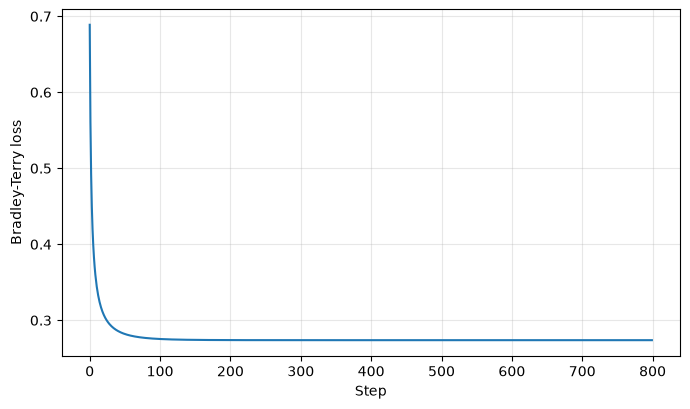

In [41]:
def pairwise_acc(w, X, win, lose):
    return float(((X[win]-X[lose]) @ w > 0).mean())
acc_tr = pairwise_acc(w_hat, X, win[tr], lose[tr])
acc_te = pairwise_acc(w_hat, X, win[te], lose[te])
cos = float(w_hat @ w_true/(np.linalg.norm(w_hat)*np.linalg.norm(w_true)))
print(f'train={acc_tr:.3f} | held-out pairs={acc_te:.3f} | cosine={cos:.3f}')
print('응답 집합은 공유하므로 새로운 응답에 대한 일반화 평가와는 다르다.')
plt.plot(hist); plt.xlabel('Step'); plt.ylabel('Bradley-Terry loss')
plt.tight_layout(); plt.show()

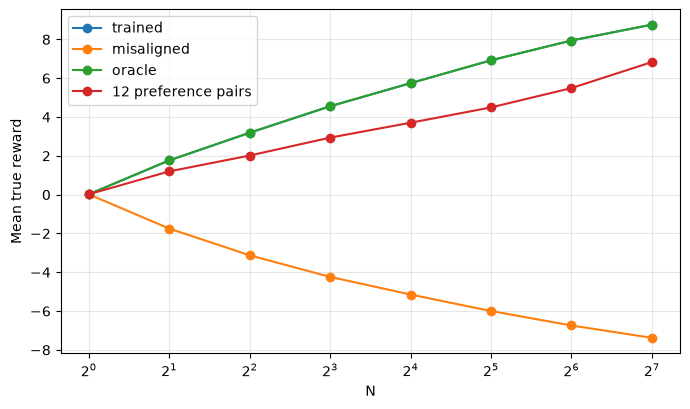

w_bad=-w_true는 의도적으로 만든 극단적인 보상 해킹 예시이다.


In [42]:
def best_of_n(w_score, X, r_true, n, trials=4000, seed=0):
    if n < 1 or trials < 1:
        raise ValueError('n and trials must be positive')
    r = np.random.default_rng(seed)
    candidates = r.integers(0, len(X), size=(trials, n))
    scores = (X @ w_score)[candidates]
    selected = candidates[np.arange(trials), scores.argmax(axis=1)]
    return float(r_true[selected].mean())
Ns = [1, 2, 4, 8, 16, 32, 64, 128]
w_bad = -w_true.copy()  # 의도적인 반정렬로 실패 사례를 재현한다.
w_few, hist_few = train_reward_model(X, win[:12], lose[:12], d, lr=.2, steps=400)
curve_hat = [best_of_n(w_hat, X, r_true, n) for n in Ns]
curve_bad = [best_of_n(w_bad, X, r_true, n) for n in Ns]
curve_orc = [best_of_n(w_true, X, r_true, n) for n in Ns]
curve_few = [best_of_n(w_few, X, r_true, n) for n in Ns]
for label, curve in [('trained', curve_hat), ('misaligned', curve_bad),
                     ('oracle', curve_orc), ('12 preference pairs', curve_few)]:
    plt.plot(Ns, curve, 'o-', label=label)
plt.xscale('log', base=2); plt.xlabel('N'); plt.ylabel('Mean true reward')
plt.legend(); plt.tight_layout(); plt.show()
print('w_bad=-w_true는 의도적으로 만든 극단적인 보상 해킹 예시이다.')

In [43]:
# ===== 문제 7 자동 검증 =====
assert abs(sigmoid(0.0) - 0.5) < 1e-12
assert sigmoid(np.array([-1000.0, 1000.0]))[0] < 1e-9
assert hist[-1] < hist[0] and hist[-1] < np.log(2)
assert acc_te > 0.75, '홀드아웃 쌍별 정확도가 0.75 이상이어야 합니다'
assert cos > 0.9, 'w_hat 은 w_true 와 방향이 거의 같아야 합니다'
assert curve_hat[-1] > curve_hat[0], '정렬된 보상 모델은 N 증가 시 진짜 보상이 올라야 합니다'
assert curve_bad[-1] < curve_bad[0], '어긋난 보상 모델은 N 증가 시 진짜 보상이 내려가야 합니다'
assert (curve_orc[-1] - curve_few[-1]) > (curve_orc[1] - curve_few[1]),     '데이터가 적은 보상 모델은 N 이 커질수록 oracle 과의 격차가 벌어져야 합니다'
print('문제 7 통과')

문제 7 통과


### 문제 7-7 (서술)

(a) 강의 자료의 2단계는 사람에게 **절대 점수**가 아니라 **순위(D > B = A > C)** 를 매기게 한다.
    Bradley-Terry 손실 식을 근거로 왜 순위 방식이 유리한지 설명하시오.

(b) 7-6의 결과를 근거로, InstructGPT 3단계에서 PPO를 쓰면서
    *"작은 변화를 점진적으로 학습시키는 접근"* 을 택한 이유를 설명하시오.

In [44]:
print("(a) Bradley-Terry는 절대 점수 대신 보상 차이 r(a)-r(b)로 비교 확률을 학습한다. "
      "평가자마다 점수 척도가 달라도 쌍별 비교는 상대적으로 일관될 수 있고, 보상에 공통 상수를 더해도 순위가 보존된다. "
      "동률은 승패로 임의 처리하지 않고 제외하거나 연성 레이블/동률 모형으로 다루어야 한다.")
print(f"(b) 학습 보상으로 고른 진짜 보상은 N=1의 {curve_hat[0]:.3f}에서 N=128의 {curve_hat[-1]:.3f}로 변하지만, "
      f"반정렬 보상에서는 {curve_bad[0]:.3f}→{curve_bad[-1]:.3f}로 악화된다. "
      "PPO의 제한된 정책 갱신과 기준 정책에 대한 KL 제약은 불완전한 보상에 대한 과도한 최적화를 완화한다. "
      "이는 보상 해킹을 완전히 방지하는 보장은 아니며 독립 평가가 필요하다.")

(a) Bradley-Terry는 절대 점수 대신 보상 차이 r(a)-r(b)로 비교 확률을 학습한다. 평가자마다 점수 척도가 달라도 쌍별 비교는 상대적으로 일관될 수 있고, 보상에 공통 상수를 더해도 순위가 보존된다. 동률은 승패로 임의 처리하지 않고 제외하거나 연성 레이블/동률 모형으로 다루어야 한다.
(b) 학습 보상으로 고른 진짜 보상은 N=1의 0.017에서 N=128의 8.758로 변하지만, 반정렬 보상에서는 0.017→-7.379로 악화된다. PPO의 제한된 정책 갱신과 기준 정책에 대한 KL 제약은 불완전한 보상에 대한 과도한 최적화를 완화한다. 이는 보상 해킹을 완전히 방지하는 보장은 아니며 독립 평가가 필요하다.


---
# 문제 8. 종합 서술 (5점)

앞의 문제 1~7에서 얻은 **구체적인 수치**를 최소 4개 이상 인용하여 다음 주제로
A4 1장 분량(600~900자)의 글을 작성하시오.

> **"거대 언어 모델의 규모 경쟁은 무엇을 얻고 무엇을 잃었는가"**

다음을 반드시 포함할 것.

1. 규모 확장이 **구조적 혁신이 아니라 양적 확장**이었다는 근거 (문제 1, 2)
2. 규모 확장의 **비용과 진입 장벽**, 환경 영향 (문제 3)
3. 규모 확장으로 **해결되지 않는 문제** (문제 6: 편향·유해성·진실성)
4. 그에 대한 대응으로서의 **RLHF**와 **오픈소스/라이선스 노선** (문제 7, 강의의 OPT·BLOOM·RAIL)

In [45]:
essay = (
    f"거대 언어 모델의 규모 경쟁은 같은 디코더 원리를 더 많은 층과 넓은 벡터로 확장하여 범용적 생성 능력을 추구한 과정이다. "
    f"표의 9개 모델 중 {(df.d_head == 128).sum()}개가 헤드 차원 128을 공유하고, 모수와 Ld²의 상관은 {corr_ld2:.3f}이다. "
    "표준 블록의 네 투영은 4d², 두 FFN은 8d²이므로 근사 모수는 12Ld²이다. "
    "이는 양적 확장의 근거이지만 모든 모델의 구조가 같다는 뜻은 아니다. 게이트형 FFN과 어텐션 공유 방식에 따른 예외도 남는다. "
    f"GPT-3의 학습량은 {C_gpt3:.2e} FLOPs이고, V100 한 장 355년은 MFU {mfu_gpt3_v100:.1%}에 대응한다. "
    f"A100 1024장으로 30일 학습하면 GPU 사용량은 {gpu_hours:,}시간, 가정한 비용은 {cost_usd:,.0f}달러다. "
    f"PUE를 반영한 전력은 {kwh:,.0f}kWh, 탄소는 {tco2:.1f}톤으로, 인프라 집중과 환경 부담을 수치로 드러낸다. "
    "그러나 더 많은 계산이 곧 진실성을 뜻하지는 않는다. 바이그램 실험처럼 가능도 최대화는 반복과 잘못된 문장도 만들며, "
    "데이터의 편향과 유해성도 옮겨진다. 단어 삭제만으로 생성 차단을 보장할 수도 없다. "
    f"선호 학습의 홀드아웃 정확도는 {acc_te:.3f}이며, RLHF는 사람의 판단을 목적에 더하는 대응이다. "
    "다만 보상이 어긋나면 Best-of-N 탐색을 키울수록 실제 만족도가 내려간다. "
    "OPT·BLOOM 같은 공개 노선은 접근성과 검증 기회를 넓히고 RAIL은 책임 있는 이용 조건을 제시한다. "
    "공개와 라이선스만으로 자원 격차나 유해 출력이 사라지지는 않으므로, 효율화와 외부 검증, 이용 책임을 함께 설계해야 한다."
)
print(essay)
print('글자 수(공백 포함):', len(essay))
assert 600 <= len(essay) <= 900

거대 언어 모델의 규모 경쟁은 같은 디코더 원리를 더 많은 층과 넓은 벡터로 확장하여 범용적 생성 능력을 추구한 과정이다. 표의 9개 모델 중 6개가 헤드 차원 128을 공유하고, 모수와 Ld²의 상관은 0.982이다. 표준 블록의 네 투영은 4d², 두 FFN은 8d²이므로 근사 모수는 12Ld²이다. 이는 양적 확장의 근거이지만 모든 모델의 구조가 같다는 뜻은 아니다. 게이트형 FFN과 어텐션 공유 방식에 따른 예외도 남는다. GPT-3의 학습량은 3.15e+23 FLOPs이고, V100 한 장 355년은 MFU 22.5%에 대응한다. A100 1024장으로 30일 학습하면 GPU 사용량은 737,280시간, 가정한 비용은 1,474,560달러다. PUE를 반영한 전력은 353,894kWh, 탄소는 141.6톤으로, 인프라 집중과 환경 부담을 수치로 드러낸다. 그러나 더 많은 계산이 곧 진실성을 뜻하지는 않는다. 바이그램 실험처럼 가능도 최대화는 반복과 잘못된 문장도 만들며, 데이터의 편향과 유해성도 옮겨진다. 단어 삭제만으로 생성 차단을 보장할 수도 없다. 선호 학습의 홀드아웃 정확도는 0.860이며, RLHF는 사람의 판단을 목적에 더하는 대응이다. 다만 보상이 어긋나면 Best-of-N 탐색을 키울수록 실제 만족도가 내려간다. OPT·BLOOM 같은 공개 노선은 접근성과 검증 기회를 넓히고 RAIL은 책임 있는 이용 조건을 제시한다. 공개와 라이선스만으로 자원 격차나 유해 출력이 사라지지는 않으므로, 효율화와 외부 검증, 이용 책임을 함께 설계해야 한다.
글자 수(공백 포함): 774


---
## 실습을 마치며

| 문제 | 확인한 사실 |
|---|---|
| 1 | 9개 모델 중 6개가 `d_head = 128`, `corr(d_model, params) ≈ 0.94` |
| 2 | `12·L·d²` 공식으로 대부분 모델의 모수를 오차 3% 이내로 재현, FFN 비중 67% |
| 3 | GPT-3 = 3.15e23 FLOPs, V100 MFU 22%, A100 1,024장 30일 = 147만 달러 / 142 tCO₂ |
| 4 | 인과적 마스크만으로 자동 회귀성이 보장됨, `n_head`는 모수 수와 무관 |
| 5 | 행렬곱 AI = `n/3`(증가), 행렬-벡터곱 AI = 1.0(상수) → 배칭이 필수 |
| 6 | 확률 모델의 목표에 진실성 항이 없음, 데이터가 생성 가능 범위의 상한 |
| 7 | 순위 2,400쌍으로 보상 모델 복원(정확도 0.86), 정렬이 깨지면 탐색이 해가 됨 |

**더 해볼 것 (선택 과제)**

- 문제 4의 어텐션에 LayerNorm·FFN·residual을 붙여 디코더 블록 1개를 완성하고,
  문제 6의 문자 단위 데이터로 작은 GPT를 numpy 역전파로 학습해 보기
- 문제 5의 계산 강도 분석을 KV 캐시가 있는 추론에 적용해, 문맥 길이 `T` 에 따른
  메모리 전송량 증가를 계산하기
- 문제 7의 보상 모델을 문제 6의 생성 모델에 연결해 Best-of-N 재순위화를 실제로 적용하기

NumPy manual backward: finite differences, CUDA autograd, causality checks passed
NumPy manual step=1/150 loss=5.2856
NumPy manual step=50/150 loss=3.6031
NumPy manual step=100/150 loss=2.7042
NumPy manual step=150/150 loss=2.1186
cuda GPT step=1/500 loss=5.2893
cuda GPT step=50/500 loss=3.2308
cuda GPT step=100/500 loss=1.8790
cuda GPT step=150/500 loss=1.0659
cuda GPT step=200/500 loss=0.5234
cuda GPT step=250/500 loss=0.3298
cuda GPT step=300/500 loss=0.2424
cuda GPT step=350/500 loss=0.2177
cuda GPT step=400/500 loss=0.1415
cuda GPT step=450/500 loss=0.1526
cuda GPT step=500/500 loss=0.1635
[numpy] 거대 언어 모델은 모을 통텐션 목더 모델은 통세모델의 헤더 수 많에 어있다. 수델을 지표는 채향된 연산여 벡을 있다. 계산은 먹께 양에 채로 했러로 델산다. 앞학습 많의 연산은 수이다. 행렬 지렬 학리한 가으베화와 연산기의 치다. 딥렬한 계. 성, 집퓨축를 초계, 행렬
[cuda] 거대 언어 모델은 재학습 시 미세조정의 과정 없이도 특정 과업에 대한 소수의 예시를 프롬프트에 입력함으로써 해당 과업을 수행한다. 이러한 문맥 내 학습은 모델의 모수를 조정하지 않아도 특정 과업을 수행할 수 있다는 장점이 있다. 그러나 거대 언어 모델은 통계 기반의 확
{'numpy_train_ppl': 7.9319365666153105, 'cuda_train_ppl': 1.202990223023156, 'num

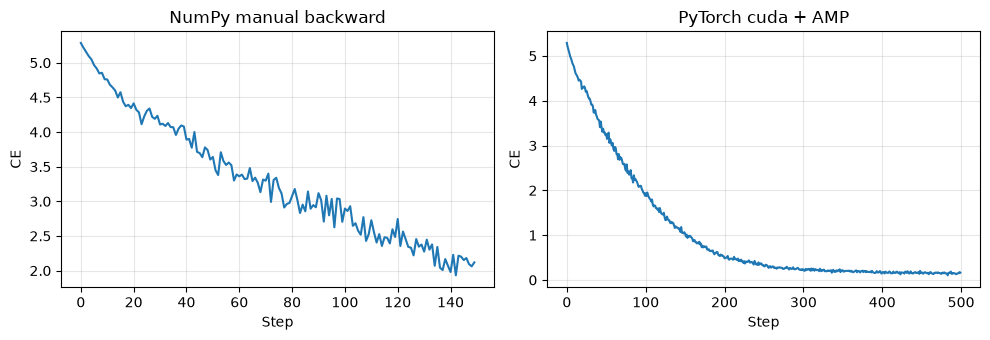

In [46]:
# 선택 과제 1: NumPy 수동 역전파 GPT + 동일 구조 CUDA GPT 학습
from week12.optional_gpt import run_optional_gpt
gpt_results = run_optional_gpt(CORPUS, HOLDOUT, output_dir=ROOT/'week12'/'outputs', device=DEVICE)

,T,batch,weight_GiB,cache_GiB,kv_write_MiB,traffic_GiB,FLOPs,AI
0,128,1,324.0,0.5625,4.5,324.566895,348496330752,0.999986
1,512,1,324.0,2.2500,4.5,326.254395,350308270080,0.999987
2,2048,1,324.0,9.0000,4.5,333.004395,357556027392,0.999987
3,8192,1,324.0,36.0000,4.5,360.004395,386547056640,0.999988
4,32768,1,324.0,144.0000,4.5,468.004395,502511173632,0.999991
5,131072,1,324.0,576.0000,4.5,900.004395,966367641600,0.999995
6,128,8,324.0,4.5000,36.0,328.535156,2787970646016,7.903264
7,512,8,324.0,18.0000,36.0,342.035156,2802466160640,7.630795
8,2048,8,324.0,72.0000,36.0,396.035156,2860448219136,6.726676
9,8192,8,324.0,288.0000,36.0,612.035156,3092376453120,4.705612


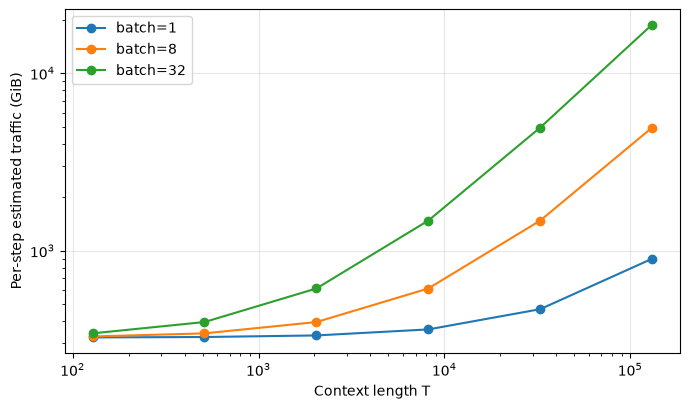

분석식만 계산하며 큰 텐서를 할당하지 않는다. KV 캐시는 O(T), 새 토큰 attention FLOPs도 O(T)이다. 가중치·KV 최소 이동량의 단순화이며 activation·통신·캐시 적중·GQA 효과는 제외한다.


In [47]:
# 선택 과제 2: KV cache가 있는 한 토큰 decode의 메모리 이동과 AI
def kv_decode_analysis(T, d=12288, L=96, batch=1, dtype_bytes=2):
    # 표준 MHA, FFN=4d, weight tying; 매 decode step, 모든 레이어 합계.
    # 가중치는 배치 내 재사용, 과거 KV는 매 step 읽고 새 K/V를 쓴다.
    weights = L*12*d*d*dtype_bytes
    kv_read = L*2*batch*T*d*dtype_bytes
    kv_write = L*2*batch*d*dtype_bytes
    flops = L*batch*(24*d*d + 4*T*d)
    traffic = weights+kv_read+kv_write
    return dict(T=T, batch=batch, weight_GiB=weights/1024**3,
        cache_GiB=kv_read/1024**3, kv_write_MiB=kv_write/1024**2,
        traffic_GiB=traffic/1024**3, FLOPs=flops, AI=flops/traffic)
kv_df = pd.DataFrame([kv_decode_analysis(T, batch=b)
    for b in [1, 8, 32] for T in [128, 512, 2048, 8192, 32768, 131072]])
display(kv_df)
for b, rows_ in kv_df.groupby('batch'):
    plt.loglog(rows_['T'], rows_.traffic_GiB, 'o-', label=f'batch={b}')
plt.xlabel('Context length T'); plt.ylabel('Per-step estimated traffic (GiB)')
plt.legend(); plt.tight_layout(); plt.show()
print('분석식만 계산하며 큰 텐서를 할당하지 않는다. KV 캐시는 O(T), 새 토큰 attention FLOPs도 O(T)이다. '
      '가중치·KV 최소 이동량의 단순화이며 activation·통신·캐시 적중·GQA 효과는 제외한다.')

In [48]:
# 선택 과제 3: 실제 바이그램 생성문에 사람 선호 쌍을 지정하고 보상 재순위화
def response_features(text):
    return np.array([len(text)/100, output_entropy(text)/8 if text else 0,
        repetition_rate(text), text.count('.')/10,
        text.count('모델')/10, text.count('학습')/10,
        text.count('유해')/10, text.count('확률')/10], dtype=float)

# 실제 출력 간의 수동 선호 예시. 실서비스에서는 외부 평가자가 라벨링해야 한다.
preference_pairs = [
    ('거대 언어 모델은 학습 데이터에서 다음 문자의 확률을 배운다.', '모델은 모델은 모델은 모델은 모델은 모델은 '),
    ('학습 데이터의 편향과 유해성을 완화해야 한다.', '유해 유해 유해 유해 유해 유해 유해 유해 '),
    ('행렬곱의 계산 강도가 높으면 연산 장치를 활용하기 쉽다.', '다다다다다다다다다다다다다다다다다다다다'),
    ('확률이 높다고 내용의 진실성이 보장되지는 않는다.', '모델모델모델모델모델모델모델모델모델모델'),
    ('거대 언어 모델은 통계 기반의 모델이다.', '이다. 이다. 이다. 이다. 이다. 이다. 이다.'),
    ('자동 회귀 모델은 앞의 토큰을 이용하여 다음 토큰을 생성한다.', '은 은 은 은 은 은 은 은 은 은 은 은 은 은 '),
]
pref_X = np.array([response_features(t) for pair in preference_pairs for t in pair])
feature_mean, feature_scale = pref_X.mean(0), pref_X.std(0)
feature_scale[feature_scale < 1e-8] = 1
pref_X = (pref_X-feature_mean)/feature_scale
rerank_w, rerank_history = train_reward_model(pref_X, np.arange(0,len(pref_X),2),
    np.arange(1,len(pref_X),2), pref_X.shape[1], lr=.05, steps=300)
candidates_text = [generate(P_best, stoi, itos, PROMPT, n_new=140,
    strategy='top_p', p=.9, temperature=.9, seed=100+i) for i in range(64)]
features = (np.array([response_features(t[len(PROMPT):]) for t in candidates_text])-
            feature_mean)/feature_scale
scores = features @ rerank_w
rerank_df = pd.DataFrame({'text':candidates_text, 'reward':scores,
    'repetition':[repetition_rate(t[len(PROMPT):]) for t in candidates_text]})
print('첫 후보:', candidates_text[0])
for count in [1, 4, 16, 64]:
    best = int(np.argmax(scores[:count]))
    print(f'Best-of-{count}: score={scores[best]:.4f} | {candidates_text[best]}')
display(rerank_df.sort_values('reward', ascending=False).head(5))
print('합성 특징 X의 보상과 텍스트 특징을 혼용하지 않고 텍스트용 보상을 다시 학습했다. '
      '작은 수동 선호 예시와 얕은 특징만 사용하므로 문장 품질·사실성 향상을 보장하지 않는다.')

첫 후보: 거대 언어 모델은 최적으로써 조정의 활용한 언어텐션의 활용하고 지피유이 언어 연산을 수를 헤드 특정 계산, 언어 어 능은 모델의 성 서 모델의 모델을 모델을 언어의 모델의 능은 학습 지피티는 수 헤드 거대 멀티 편향성을 자원은 행할 언어 학습 모델은 벡터의 편향성을 모
Best-of-1: score=11.8740 | 거대 언어 모델은 최적으로써 조정의 활용한 언어텐션의 활용하고 지피유이 언어 연산을 수를 헤드 특정 계산, 언어 어 능은 모델의 성 서 모델의 모델을 모델을 언어의 모델의 능은 학습 지피티는 수 헤드 거대 멀티 편향성을 자원은 행할 언어 학습 모델은 벡터의 편향성을 모
Best-of-4: score=12.6344 | 거대 언어 모델은 행렬곱 모수행렬곱 지피유 학습 모델을 모델은 처리 확장점이터의 소수행한 성 수 계 대 높이다. 장 연산 학습은 거대한다. 모델을 서비례하여 데이나 않아워 계산 목표는 언어 내 활용하여 기반의 경량화했다. 생성 연산 헤드 위한 모델은 활용하고 학습한 언
Best-of-16: score=12.6344 | 거대 언어 모델은 행렬곱 모수행렬곱 지피유 학습 모델을 모델은 처리 확장점이터의 소수행한 성 수 계 대 높이다. 장 연산 학습은 거대한다. 모델을 서비례하여 데이나 않아워 계산 목표는 언어 내 활용하여 기반의 경량화했다. 생성 연산 헤드 위한 모델은 활용하고 학습한 언
Best-of-64: score=13.8795 | 거대 언어 모델은 문맥 학습을 모수 단위를 함으며 담겨 언어 처리 확률 벡터에 성을 확장 구하고 양적인스하고 내용이며 단어 학습 내 거짓된 최대 거대 언어의 편향성을 아워 있을 수 조정에 연산 거대 소수 것으로 모델을 지 서는 모델은 지피티 언어 학습 있다. 거대 인스


,text,reward,repetition
29,거대 언어 모델은 문맥 학습을 모수 단위를 함으며 담겨 언어 처리 확률 벡터에 성을...,13.879544,0.036496
56,거대 언어 모델은 구축해 따른 있다. 사용한 지피유 지 모델을 편향성을 가장 산 언...,13.875687,0.058394
22,거대 언어 모델은 처리 대한 장 학습 없이 크기 언어 언어 학습을 최대중한 모델을 ...,13.852526,0.072993
62,거대 언어 모델은 거대 지 언어 언어 지속적으로 목표는 거짓된 과업에 아도 트에 행...,13.070183,0.029197
33,거대 언어 모델은 확률 언어 처리와 있으로 데이며 계산을 멀티는 내용할 있을 있으로...,12.996463,0.087591


합성 특징 X의 보상과 텍스트 특징을 혼용하지 않고 텍스트용 보상을 다시 학습했다. 작은 수동 선호 예시와 얕은 특징만 사용하므로 문장 품질·사실성 향상을 보장하지 않는다.
